# Image2Video

**One portrait + one script → one talking-head MP4.**

This notebook runs the complete pipeline on a free Colab **T4 GPU**:

```
script ──► neural TTS (edge-tts / Piper / gTTS) ──► 16 kHz WAV
                                                        │
portrait JPG/PNG ───────────────────────────────────────┴──► SadTalker ──► MP4
```

* No API key, no account, no paid service.
* Speech: **edge-tts** (Microsoft neural voices), with the fully offline **Piper**
  model and **gTTS** as fallbacks.
* Animation: the official **SadTalker** checkpoints (CVPR 2023, Apache-2.0).
* Everything in this notebook is generated from the project sources, so what you
  run here is exactly the code in the repository.

## 0. Before you start

1. **Enable a GPU**: `Runtime → Change runtime type → Hardware accelerator: T4 GPU`.
   The pipeline also runs on CPU, but roughly 20x slower.
2. **Expect ~8 minutes for the setup cell** below: it downloads a Python 3.10
   interpreter, PyTorch (2 GB) and 1.2 GB of model checkpoints.
3. Why Python 3.10? SadTalker's `face3d` code uses `np.float` (removed in NumPy
   1.24) and `np.VisibleDeprecationWarning` (removed in NumPy 2.0), so the stack
   must stay on **NumPy 1.23.5**. NumPy 1.23.5 has no wheels for Python 3.12/3.13,
   which is what the Colab runtime itself ships. The setup cell therefore creates
   an isolated 3.10 environment in `/content/.s2p-venv`.
4. The setup is **idempotent**: re-running the setup cell after a disconnect is fast.

In [1]:
#@title 1. Check the GPU { display-mode: "form" }
import subprocess

try:
    info = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    info = ""

if info:
    print(info)
    driver = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
        capture_output=True, text=True,
    ).stdout.strip()
    print(driver)
else:
    print(
        "\n*** No GPU detected. ***\n"
        "Runtime -> Change runtime type -> Hardware accelerator: T4 GPU\n"
        "The pipeline still works on CPU, it is just much slower."
    )

GPU 0: Tesla T4 (UUID: GPU-cb4c72b7-c934-fec5-7756-68ec79d74483)
Tesla T4, 15360 MiB, 580.82.07


## 1. Write the project files

The first cell creates the folders (`%%writefile` cannot do that). The following
cells then recreate the project inside `/content/Script2Presenter` exactly as it
lives in the repository: the pinned dependency files, the setup script, and the `s2p`
package. Nothing is executed yet — the cell after them builds the environment.

| module | responsibility |
|---|---|
| `s2p/config.py` | locate SadTalker, checkpoints, output folders |
| `s2p/patches.py` | idempotent fixes for Pillow 10, PyTorch 2.6, basicsr, optional gfpgan |
| `s2p/audio_utils.py` | convert anything to 16 kHz mono WAV, concatenate, probe |
| `s2p/tts.py` | edge-tts → Piper → gTTS fallback chain, sentence chunking |
| `s2p/sadtalker_backend.py` | wraps `CropAndExtract`, `Audio2Coeff`, `AnimateFromCoeff` |
| `s2p/pipeline.py` | orchestration, validation, `manifest.json` |
| `s2p/ui.py` | Gradio front-end |
| `s2p/cli.py` | `python -m s2p.cli` |

In [2]:
# Create the folders the next cells write into (safe to re-run)
import os

PROJECT = "/content/Script2Presenter"
for path in [
    PROJECT,
    f"{PROJECT}/s2p",
    f"{PROJECT}/scripts",
    f"{PROJECT}/tests",
    f"{PROJECT}/models",
    f"{PROJECT}/outputs",
    "/content/input",
    "/content/output",
]:
    os.makedirs(path, exist_ok=True)

print("project :", PROJECT)
print("venv    :", "/content/.s2p-venv")
print("sadtalker:", "/content/SadTalker")

project : /content/Script2Presenter
venv    : /content/.s2p-venv
sadtalker: /content/SadTalker


In [3]:
%%writefile /content/Script2Presenter/requirements-colab.txt
# Runtime dependencies for the Google Colab GPU environment (Python 3.10).
#
# Install order matters and is automated by scripts/setup_colab.sh:
#   1. torch + torchvision from the CUDA 11.8 wheel index
#   2. this file (with constraints.txt applied)
#   3. basicsr / facexlib / gfpgan with --no-deps (their metadata is stale)
#
# ---------------------------------------------------------------------------
# Numerical stack
# ---------------------------------------------------------------------------
# numpy MUST stay on the 1.23 line. SadTalker's face3d code uses
#   * np.VisibleDeprecationWarning   (removed in numpy 2.0)
#   * np.float                       (removed in numpy 1.24)
# See s2p/patches.py::required_numpy_spec.  Python 3.10/3.11 is required because
# numpy 1.23.5 has no wheels for Python 3.12+.
numpy==1.23.5
scipy==1.10.1
numba==0.58.1
llvmlite==0.41.1
librosa==0.10.2.post1
soundfile==0.12.1
scikit-image==0.19.3
# imageio 2.19 keeps the classic `imageio.get_writer(..., fps=)` API that
# SadTalker relies on (deprecated in imageio 2.28+). scikit-image must therefore
# stay on 0.19.x as well: 0.22+ requires imageio>=2.27.
imageio==2.19.3
# 0.4.7 (SadTalker's pin) imports the legacy `pkg_resources`, which no longer
# exists in setuptools >= 81 -> "No module named 'pkg_resources'" at the very end
# of the render. 0.5.1 is the first release that uses importlib.resources and is
# API compatible with the calls imageio 2.19 makes (get_ffmpeg_exe,
# write_frames, count_frames_and_secs).
imageio-ffmpeg==0.5.1
# Legacy helpers in this 2023-era stack (tb-nightly, diffjpeg, ...) still expect
# pkg_resources at runtime, and `pip --no-build-isolation` uses this setuptools
# to build basicsr. setuptools 81 removed pkg_resources.
setuptools<81
opencv-python-headless==4.9.0.80
pillow==9.5.0
PyYAML==6.0.1
tqdm==4.66.4
yacs==0.1.8
# animate.py uses pydub.AudioSegment for the duration of the generated video.
# pydub needs the stdlib `audioop` module, which was removed in Python 3.13.
pydub==0.25.1
safetensors==0.4.3
# `src/face3d/models/networks.py` imports kornia at inference time too.
kornia==0.6.12

# ---------------------------------------------------------------------------
# SadTalker / GFPGAN helper libraries (installed with --no-deps)
# ---------------------------------------------------------------------------
# Their setup metadata pins ancient, mutually incompatible versions, so we
# install them without dependencies and provide the few modules they actually
# import at runtime:
addict==2.4.0
future==1.0.0
lmdb==1.4.1
filterpy==1.4.5

# ---------------------------------------------------------------------------
# Speech synthesis - all free, no API key, no account
# ---------------------------------------------------------------------------
edge-tts==7.3.1
piper-tts==1.8.0
# onnxruntime is pip-installed by piper-tts; pin a version that still accepts
# numpy 1.23.
onnxruntime==1.16.3
gTTS==2.5.1

# ---------------------------------------------------------------------------
# Web UI
# ---------------------------------------------------------------------------
# Gradio 4.44.1 is the last 4.x release and the newest one whose dependencies
# accept numpy 1.x.  huggingface-hub is pinned because 0.30+ removed HfFolder.
gradio==4.44.1
huggingface-hub==0.25.2


Writing /content/Script2Presenter/requirements-colab.txt


In [4]:
%%writefile /content/Script2Presenter/constraints.txt
# Hard constraints applied to *every* pip invocation in the Colab environment.
# If a package cannot be satisfied together with numpy 1.23.5, pip fails loudly
# instead of silently upgrading numpy and breaking SadTalker at runtime.
numpy==1.23.5


Writing /content/Script2Presenter/constraints.txt


In [5]:
%%writefile /content/Script2Presenter/scripts/setup_colab.sh
#!/usr/bin/env bash
# ---------------------------------------------------------------------------
# Prepare a Google Colab (or any Ubuntu) GPU machine for Script2Presenter.
#
#   bash scripts/setup_colab.sh [/content/Script2Presenter]
#
# What it does
#   1. installs `uv` (fast, no Anaconda licence questions)
#   2. downloads a standalone CPython 3.10 (numpy 1.23.5 has no 3.12+ wheels)
#   3. creates /content/.s2p-venv and installs the pinned dependency set
#   4. clones the official SadTalker checkout at a pinned commit
#   5. downloads the checkpoints
#   6. verifies the environment (torch + CUDA + numpy)
#
# Safe to re-run: every step is skipped when it is already done.
# ---------------------------------------------------------------------------
set -euo pipefail

PROJECT_DIR="${1:-/content/Script2Presenter}"
VENV="${S2P_VENV:-/content/.s2p-venv}"
SADTALKER_DIR="${SADTALKER_DIR:-/content/SadTalker}"
SADTALKER_COMMIT="cd4c0465ae0b54a6f85af57f5c65fec9fe23e7f8"
PYTHON_VERSION="${S2P_PYTHON:-3.10}"
SIZE="${S2P_SIZE:-256}"

log() { printf '\n\033[1;36m[setup]\033[0m %s\n' "$*"; }

log "project:  $PROJECT_DIR"
log "venv:     $VENV (python $PYTHON_VERSION)"

# --- 1. uv ----------------------------------------------------------------
if ! python -m uv --version >/dev/null 2>&1; then
  log "installing uv ..."
  python -m pip install -q uv
fi
python -m uv --version

# --- 2/3. interpreter + dependencies --------------------------------------
if [ ! -x "$VENV/bin/python" ]; then
  log "creating the python $PYTHON_VERSION environment ..."
  python -m uv venv --python "$PYTHON_VERSION" "$VENV"
fi
PY="$VENV/bin/python"
"$PY" --version

if ! "$PY" -c "import torch" >/dev/null 2>&1; then
  log "installing torch (CUDA build, ~2 GB) ..."
  python -m uv pip install --python "$PY" torch==2.0.1 torchvision==0.15.2
fi

log "installing the pinned runtime dependencies ..."
python -m uv pip install --python "$PY" \
  -c "$PROJECT_DIR/constraints.txt" \
  -r "$PROJECT_DIR/requirements-colab.txt"

log "installing basicsr / facexlib / gfpgan (without their stale metadata) ..."
# These three only ship sdists and their setup.py declares
# setup_requires=['cython', 'numpy', 'torch']. With build isolation pip would try
# to download a whole second torch (~600 MB) into a throw-away build env, and
# basicsr's setup.py imports torch at build time - hence --no-build-isolation
# with torch already present.  --no-deps keeps their 2023 pins (tb-nightly, av,
# face_alignment) out of the environment.
# setuptools must stay below 81: it is what builds basicsr here (via
# --no-build-isolation) and 81 dropped pkg_resources, which several of these
# 2023-era packages still import at runtime. Must match requirements-colab.txt.
python -m uv pip install --python "$PY" -q pip "setuptools<81" wheel cython
"$PY" -m pip install -q --no-build-isolation --no-deps \
  basicsr==1.4.2 facexlib==0.3.0 gfpgan==1.3.8
"$PY" -c "import basicsr, facexlib, gfpgan; print('basicsr/facexlib/gfpgan OK')"

log "guarding the numpy pin ..."
"$PY" - <<'PYEOF'
import sys
import numpy
if numpy.__version__ != "1.23.5":
    sys.exit(
        f"numpy drifted to {numpy.__version__}; SadTalker requires 1.23.5. "
        "Re-run: pip install -c constraints.txt numpy==1.23.5"
    )
print("numpy", numpy.__version__, "OK")
PYEOF

# --- 4. SadTalker --------------------------------------------------------
if [ ! -d "$SADTALKER_DIR/.git" ]; then
  log "cloning SadTalker ..."
  git clone -q https://github.com/OpenTalker/SadTalker.git "$SADTALKER_DIR"
fi
log "pinning SadTalker to $SADTALKER_COMMIT ..."
git -C "$SADTALKER_DIR" fetch -q --depth 1 origin "$SADTALKER_COMMIT" 2>/dev/null || \
  git -C "$SADTALKER_DIR" fetch -q origin
git -C "$SADTALKER_DIR" checkout -q "$SADTALKER_COMMIT" 2>/dev/null || \
  git -C "$SADTALKER_DIR" reset -q --hard "$SADTALKER_COMMIT"

# --- 5. checkpoints ------------------------------------------------------
log "downloading the checkpoints (size $SIZE) ..."
"$PY" "$PROJECT_DIR/scripts/download_checkpoints.py" --dest "$SADTALKER_DIR" --size "$SIZE"

# --- 6. verify -----------------------------------------------------------
log "verifying the environment ..."
cd "$PROJECT_DIR"
S2P_SADTALKER_ROOT="$SADTALKER_DIR" "$PY" - <<'PYEOF'
import os, sys

import torch, numpy, cv2, librosa, soundfile, pydub, edge_tts, piper, gradio, safetensors
import kornia, skimage

print(f"  python      : {sys.version.split()[0]}")
print(f"  torch       : {torch.__version__}")
print(f"  cuda        : {torch.cuda.is_available()} "
      f"({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu only'})")
print(f"  numpy       : {numpy.__version__}")
print(f"  gradio      : {gradio.__version__}")

# The render finishes with imageio.mimsave(path, frames, fps=25). Exercise that
# exact path now - a broken ffmpeg backend (e.g. a missing pkg_resources) would
# otherwise only surface after minutes of GPU work.
import tempfile
import numpy as np
import imageio
import imageio_ffmpeg

smoke_path = os.path.join(tempfile.mkdtemp(), "smoke.mp4")
imageio.mimsave(
    smoke_path, [np.zeros((64, 64, 3), dtype=np.uint8)] * 4, fps=25
)
print(f"  imageio     : {imageio.__version__} ("
      f"{os.path.basename(imageio_ffmpeg.get_ffmpeg_exe())}, "
      f"wrote {os.path.getsize(smoke_path)} bytes)")

if os.path.isfile("s2p/__init__.py"):
    import s2p
    print(f"  s2p         : {s2p.__version__}")
else:
    print("  s2p         : skipped (run the notebook's source cells first)")
PYEOF

log "done. Run the demo with:"
echo "  cd $PROJECT_DIR"
echo "  $PY -m s2p.cli --image portrait.png --text 'Hello world' --out out.mp4"
echo "  $PY -m s2p.ui --share        # optional web UI"


Writing /content/Script2Presenter/scripts/setup_colab.sh


In [6]:
%%writefile /content/Script2Presenter/scripts/download_checkpoints.py
#!/usr/bin/env python3
"""Download the official SadTalker checkpoints.

Only public, official release assets are used:

* https://github.com/OpenTalker/SadTalker/releases/tag/v0.0.2-rc
* https://github.com/xinntao/facexlib/releases  (face detection / alignment)
* https://github.com/TencentARC/GFPGAN/releases  (optional face enhancer)

A Hugging Face mirror is used automatically when GitHub is slow or unreachable.

Usage::

    python scripts/download_checkpoints.py --dest third_party/SadTalker
    python scripts/download_checkpoints.py --size 512 --with-enhancer

The script is resumable-ish: a partial file is kept as ``<name>.part`` and
re-downloaded on the next run; complete files are skipped after a size check.
"""

from __future__ import annotations

import argparse
import os
import sys
import time
import urllib.error
import urllib.request
from pathlib import Path

GH_RELEASE = "https://github.com/OpenTalker/SadTalker/releases/download/v0.0.2-rc"
HF_MIRROR = "https://huggingface.co/camenduru/SadTalker/resolve/main/new"

FACEXLIB = "https://github.com/xinntao/facexlib/releases/download"
GFPGAN = "https://github.com/TencentARC/GFPGAN/releases/download"

# (relative path, [urls], exact size in bytes or None, tags)
FILES: list[tuple[str, list[str], int | None, set[str]]] = [
    (
        "checkpoints/SadTalker_V0.0.2_256.safetensors",
        [f"{GH_RELEASE}/SadTalker_V0.0.2_256.safetensors",
         f"{HF_MIRROR}/checkpoints/SadTalker_V0.0.2_256.safetensors"],
        725_066_984,
        {"256"},
    ),
    (
        "checkpoints/SadTalker_V0.0.2_512.safetensors",
        [f"{GH_RELEASE}/SadTalker_V0.0.2_512.safetensors",
         f"{HF_MIRROR}/checkpoints/SadTalker_V0.0.2_512.safetensors"],
        725_066_984,
        {"512"},
    ),
    (
        "checkpoints/mapping_00229-model.pth.tar",
        [f"{GH_RELEASE}/mapping_00229-model.pth.tar",
         f"{HF_MIRROR}/checkpoints/mapping_00229-model.pth.tar"],
        155_521_183,
        {"crop"},
    ),
    (
        "checkpoints/mapping_00109-model.pth.tar",
        [f"{GH_RELEASE}/mapping_00109-model.pth.tar",
         f"{HF_MIRROR}/checkpoints/mapping_00109-model.pth.tar"],
        155_779_231,
        {"full"},
    ),
    (
        "gfpgan/weights/alignment_WFLW_4HG.pth",
        [f"{FACEXLIB}/v0.1.0/alignment_WFLW_4HG.pth",
         f"{HF_MIRROR}/gfpgan/weights/alignment_WFLW_4HG.pth"],
        193_670_248,
        {"core"},
    ),
    (
        "gfpgan/weights/detection_Resnet50_Final.pth",
        [f"{FACEXLIB}/v0.1.0/detection_Resnet50_Final.pth",
         f"{HF_MIRROR}/gfpgan/weights/detection_Resnet50_Final.pth"],
        109_497_761,
        {"core"},
    ),
    (
        "gfpgan/weights/GFPGANv1.4.pth",
        [f"{GFPGAN}/v1.3.0/GFPGANv1.4.pth",
         f"{HF_MIRROR}/gfpgan/weights/GFPGANv1.4.pth"],
        348_632_874,
        {"enhancer"},
    ),
    (
        "gfpgan/weights/parsing_parsenet.pth",
        [f"{FACEXLIB}/v0.2.2/parsing_parsenet.pth",
         f"{HF_MIRROR}/gfpgan/weights/parsing_parsenet.pth"],
        85_331_193,
        {"enhancer"},
    ),
]

MIN_BYTES = 1_000_000


def _human(num: float) -> str:
    for unit in ("B", "KB", "MB", "GB"):
        if num < 1024 or unit == "GB":
            return f"{num:.1f} {unit}"
        num /= 1024
    return f"{num:.1f} GB"


def _download_one(url: str, target: Path, expected: int | None) -> None:
    part = target.with_suffix(target.suffix + ".part")
    request = urllib.request.Request(url, headers={"User-Agent": "Script2Presenter/0.1"})
    with urllib.request.urlopen(request, timeout=60) as response:
        total = int(response.headers.get("Content-Length") or 0)
        if expected and total and total != expected:
            raise OSError(f"size mismatch: server says {total}, expected {expected}")
        received = 0
        last_report = 0.0
        with part.open("wb") as handle:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                handle.write(chunk)
                received += len(chunk)
                now = time.time()
                if now - last_report > 2.0:
                    last_report = now
                    pct = f"{100 * received / total:5.1f}%" if total else "  ?  "
                    print(f"    {pct}  {_human(received)}", end="\r", flush=True)
    print(f"    {_human(received)} downloaded" + " " * 20)

    size = part.stat().st_size
    if expected and size != expected:
        part.unlink(missing_ok=True)
        raise OSError(f"size mismatch after download: {size} != {expected}")
    if size < MIN_BYTES:
        part.unlink(missing_ok=True)
        raise OSError(f"downloaded file is suspiciously small ({size} bytes)")
    os.replace(part, target)


def download(target: Path, urls: list[str], expected: int | None, retries: int = 2) -> bool:
    if target.is_file() and target.stat().st_size >= (expected or MIN_BYTES):
        print(f"  = {target} (already present, {_human(target.stat().st_size)})")
        return True
    for url in urls:
        for attempt in range(1, retries + 1):
            print(f"  > {target}  <-  {url} (attempt {attempt})")
            try:
                target.parent.mkdir(parents=True, exist_ok=True)
                _download_one(url, target, expected)
                print(f"  + {target} ({_human(target.stat().st_size)})")
                return True
            except (urllib.error.URLError, OSError, TimeoutError) as exc:
                print(f"    failed: {exc}")
                time.sleep(2 * attempt)
    print(f"  ! could not download {target}")
    return False


def selected_tags(size: str, with_enhancer: bool, with_full: bool) -> set[str]:
    tags = {"core"}
    if size in ("256", "both"):
        tags.add("256")
    if size in ("512", "both"):
        tags.add("512")
    tags.add("crop")
    if with_full:
        tags.add("full")
    if with_enhancer:
        tags.add("enhancer")
    return tags


def main(argv: list[str] | None = None) -> int:
    root = Path(__file__).resolve().parent.parent
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--dest",
        default=str(root / "third_party" / "SadTalker"),
        help="SadTalker checkout (default: %(default)s)",
    )
    parser.add_argument("--size", default="256", choices=["256", "512", "both"])
    parser.add_argument("--with-enhancer", action="store_true",
                        help="also fetch the GFPGAN enhancer weights (+430 MB)")
    parser.add_argument("--with-full", action="store_true",
                        help="also fetch the mapping network used by --preprocess full")
    parser.add_argument("--check", action="store_true",
                        help="only report which files are missing")
    args = parser.parse_args(argv)

    dest = Path(args.dest).expanduser().resolve()
    tags = selected_tags(args.size, args.with_enhancer, args.with_full)

    wanted = [entry for entry in FILES if entry[3] & tags]
    total = sum((entry[2] or MIN_BYTES) for entry in wanted)

    print(f"SadTalker root : {dest}")
    print(f"Files          : {len(wanted)}  (~{_human(total)})")
    print(f"Selection      : {', '.join(sorted(tags))}\n")

    missing = [e for e in wanted
               if not (dest / e[0]).is_file()
               or (dest / e[0]).stat().st_size < (e[2] or MIN_BYTES)]
    if args.check:
        if not missing:
            print("All requested checkpoints are present.")
            return 0
        print("Missing:")
        for relative, _, size, _ in missing:
            print(f"  - {relative} ({_human(size or MIN_BYTES)})")
        return 1

    failures = 0
    for relative, urls, size, _ in wanted:
        if not download(dest / relative, urls, size):
            failures += 1

    print()
    if failures:
        print(f"{failures} file(s) could not be downloaded.")
        return 1
    print("All requested checkpoints are present.")
    return 0


if __name__ == "__main__":
    sys.exit(main())


Writing /content/Script2Presenter/scripts/download_checkpoints.py


In [7]:
%%writefile /content/Script2Presenter/s2p/__init__.py
"""Script2Presenter - portrait + script -> talking-head MP4.

Public entry points::

    from s2p import Script2Presenter
    app = Script2Presenter()
    result = app.run("portrait.jpg", "Hello world, this is my presentation.")

or from the command line::

    python -m s2p.cli --image portrait.jpg --text "Hello world" --out out.mp4
"""

from __future__ import annotations

__version__ = "0.1.0"

from .config import Settings, load_settings
from .pipeline import PipelineError, PipelineResult, Script2Presenter
from .sadtalker_backend import SadTalkerBackend, SadTalkerError
from .tts import TTSError, TTSResult, list_voices, synthesize

__all__ = [
    "PipelineError",
    "PipelineResult",
    "SadTalkerBackend",
    "SadTalkerError",
    "Script2Presenter",
    "Settings",
    "TTSError",
    "TTSResult",
    "__version__",
    "list_voices",
    "load_settings",
    "synthesize",
]


Writing /content/Script2Presenter/s2p/__init__.py


In [8]:
%%writefile /content/Script2Presenter/s2p/config.py
"""Central configuration for Script2Presenter.

Everything that can change between the local (CPU, no-GPU) development machine and
the Google Colab T4 runtime is resolved here, so the rest of the code never has to
guess where the SadTalker checkout or its checkpoints live.

No credentials, tokens or API keys are read or stored by this module.
"""

from __future__ import annotations

import os
from dataclasses import dataclass
from pathlib import Path

# --------------------------------------------------------------------------- #
# Constants
# --------------------------------------------------------------------------- #

PROJECT_ROOT = Path(__file__).resolve().parent.parent

#: SadTalker's audio front-end expects 16 kHz mono PCM.
TARGET_SAMPLE_RATE = 16000
TARGET_CHANNELS = 1

#: SadTalker renders at a fixed frame rate.
FPS = 25

#: Default neural voice (free Microsoft Edge TTS voice, no API key required).
DEFAULT_VOICE = "en-US-AriaNeural"

#: ``auto`` walks the provider chain in :mod:`s2p.tts`.
DEFAULT_PROVIDER = "auto"

#: SadTalker face-renderer resolutions that ship as pretrained checkpoints.
SUPPORTED_SIZES = (256, 512)
DEFAULT_SIZE = 256

#: ``crop`` keeps the animated face only, ``full`` pastes it back on the portrait.
DEFAULT_PREPROCESS = "crop"
SUPPORTED_PREPROCESS = ("crop", "extcrop", "resize", "full", "extfull")

DEFAULT_POSE_STYLE = 0
DEFAULT_BATCH_SIZE = 2
DEFAULT_EXPRESSION_SCALE = 1.0
DEFAULT_ENHANCER = None  # None | "gfpgan" | "RestoreFormer"

#: Upper bound on a single script, keeps the demo snappy and avoids abuse.
MAX_SCRIPT_CHARS = 5000

#: Candidate locations for the official SadTalker checkout, in priority order.
_SADTALKER_CANDIDATES = (
    "/content/SadTalker",
    str(PROJECT_ROOT / "third_party" / "SadTalker"),
    str(PROJECT_ROOT / "SadTalker"),
    str(PROJECT_ROOT.parent / "SadTalker"),
)


def _env_path(name: str) -> Path | None:
    value = os.environ.get(name)
    return Path(value).expanduser().resolve() if value else None


@dataclass(frozen=True)
class Settings:
    """Resolved runtime settings."""

    sadtalker_root: Path
    checkpoint_dir: Path
    output_dir: Path
    work_dir: Path
    device: str = "auto"

    @property
    def config_dir(self) -> Path:
        """SadTalker's ``src/config`` directory (holds the YAML + 3DMM prior)."""
        return self.sadtalker_root / "src" / "config"

    @property
    def face_weights_dir(self) -> Path:
        """Where facexlib looks for the alignment / detection checkpoints."""
        return self.sadtalker_root / "gfpgan" / "weights"

    def describe(self) -> dict:
        return {
            "sadtalker_root": str(self.sadtalker_root),
            "checkpoint_dir": str(self.checkpoint_dir),
            "output_dir": str(self.output_dir),
            "work_dir": str(self.work_dir),
            "device": self.device,
        }


def resolve_sadtalker_root(explicit: str | os.PathLike | None = None) -> Path:
    """Locate the official SadTalker checkout.

    Order of precedence: explicit argument, ``S2P_SADTALKER_ROOT`` env var, then a
    list of well-known locations (Colab's ``/content/SadTalker`` first).
    """
    if explicit:
        return Path(explicit).expanduser().resolve()

    env_root = _env_path("S2P_SADTALKER_ROOT")
    if env_root:
        return env_root

    for candidate in _SADTALKER_CANDIDATES:
        path = Path(candidate)
        if (path / "src" / "utils" / "init_path.py").is_file():
            return path.resolve()

    raise FileNotFoundError(
        "Could not find the SadTalker checkout. Clone it with\n"
        "    git clone https://github.com/OpenTalker/SadTalker.git /content/SadTalker\n"
        "or set the S2P_SADTALKER_ROOT environment variable to its path."
    )


def load_settings(
    sadtalker_root: str | os.PathLike | None = None,
    output_dir: str | os.PathLike | None = None,
    work_dir: str | os.PathLike | None = None,
    device: str = "auto",
) -> Settings:
    """Build a :class:`Settings` instance from arguments + environment."""
    root = resolve_sadtalker_root(sadtalker_root)
    checkpoints = _env_path("S2P_CHECKPOINT_DIR") or (root / "checkpoints")
    outputs = Path(output_dir).expanduser().resolve() if output_dir else (
        _env_path("S2P_OUTPUT_DIR") or (PROJECT_ROOT / "outputs")
    )
    work = Path(work_dir).expanduser().resolve() if work_dir else (
        _env_path("S2P_WORK_DIR") or (PROJECT_ROOT / "work")
    )
    return Settings(
        sadtalker_root=root,
        checkpoint_dir=checkpoints,
        output_dir=outputs,
        work_dir=work,
        device=device,
    )


def ensure_directories(settings: Settings) -> Settings:
    """Create the output/work/checkpoint directories if they do not exist yet."""
    settings.output_dir.mkdir(parents=True, exist_ok=True)
    settings.work_dir.mkdir(parents=True, exist_ok=True)
    settings.checkpoint_dir.mkdir(parents=True, exist_ok=True)
    # facexlib resolves its weights relative to the current working directory
    # (``<cwd>/gfpgan/weights``) and creates the folder on demand only sometimes.
    try:
        settings.face_weights_dir.mkdir(parents=True, exist_ok=True)
    except OSError:
        pass
    return settings


Writing /content/Script2Presenter/s2p/config.py


In [9]:
%%writefile /content/Script2Presenter/s2p/patches.py
"""Idempotent compatibility patches for SadTalker and its dependency stack.

SadTalker was released in 2023 against the 2023 PyTorch / NumPy / Pillow stack.
The Colab runtime of 2026 ships NumPy 2.x, Pillow >= 10 and PyTorch >= 2.6, which
breaks four separate things in the upstream code:

=========================================  ===========================================
Upstream breakage                          Fix applied here
=========================================  ===========================================
``np.VisibleDeprecationWarning`` removed   Avoided entirely: we pin ``numpy<1.24``
in NumPy 2.x                              (see :func:`required_numpy_spec`).
``np.float`` removed in NumPy 1.24         Same as above.
``Image.ANTIALIAS`` removed in Pillow 10   ``patch_pillow_antialias``
``torch.load`` defaults to                 ``patch_torch_load_weights_only``
``weights_only=True`` in PyTorch 2.6+
``basicsr`` imports the removed             ``patch_basicsr_functional_tensor``
``torchvision.transforms.functional_tensor``
``from gfpgan import GFPGANer`` is a hard   ``patch_gfpgan_lazy_import``
import of the optional enhancer
=========================================  ===========================================

Every patch writes a ``<file>.orig`` backup once and is safe to run repeatedly.
"""

from __future__ import annotations

import shutil
from dataclasses import dataclass
from pathlib import Path

__all__ = [
    "PatchResult",
    "apply_all_patches",
    "patch_basicsr_functional_tensor",
    "patch_gfpgan_lazy_import",
    "patch_pillow_antialias",
    "patch_torch_load_weights_only",
    "required_numpy_spec",
]


@dataclass
class PatchResult:
    """Outcome of a single patch."""

    name: str
    applied: bool
    detail: str

    def __str__(self) -> str:  # pragma: no cover - cosmetic
        state = "PATCHED" if self.applied else "OK      "
        return f"[{state}] {self.name}: {self.detail}"


def _backup(path: Path, backup_suffix: str = ".orig") -> Path | None:
    """Copy ``path`` to its ``.orig`` backup once. Returns the backup path."""
    backup = path.with_suffix(path.suffix + backup_suffix)
    if backup.exists():
        return None
    shutil.copy2(path, backup)
    return backup


def _replace_in_file(path: Path, old: str, new: str, backup_suffix: str = ".orig") -> tuple[bool, str]:
    """Replace ``old`` with ``new`` inside ``path``.

    Returns ``(changed, detail)``. Never overwrites an existing backup, and never
    writes a Python file that no longer compiles.
    """
    if not path.is_file():
        return False, f"file not found: {path}"
    text = path.read_text(encoding="utf-8")
    if new in text:
        return False, f"already applied: {path}"
    if old not in text:
        return False, f"pattern not found in {path}"
    updated = text.replace(old, new)
    if path.suffix == ".py":
        try:
            compile(updated, str(path), "exec")
        except SyntaxError as exc:
            return False, f"refusing to break {path.name}: {exc}"
    backup = _backup(path, backup_suffix)
    path.write_text(updated, encoding="utf-8")
    name = backup.name if backup else path.with_suffix(path.suffix + backup_suffix).name
    return True, f"{path} (backup: {name})"


def patch_pillow_antialias(sadtalker_root: Path) -> PatchResult:
    """Replace the removed ``PIL.Image.ANTIALIAS`` alias with ``Image.LANCZOS``.

    ``Image.ANTIALIAS`` was an alias of ``Image.LANCZOS`` before Pillow 10 removed
    it, so the substitution is behaviour-preserving.

    The replacement must stay a bare attribute: SadTalker calls it inline, e.g.
    ``img.resize((256, 256), Image.ANTIALIAS)``, so any trailing comment would
    swallow the closing parenthesis and make the module unimportable.  Files
    damaged by that earlier revision are repaired here.
    """
    target = Path(sadtalker_root) / "src" / "utils" / "croper.py"
    broken = "Image.LANCZOS  # LANCZOS replaced the Pillow <10 ANTIALIAS alias"

    repaired = False
    if target.is_file():
        text = target.read_text(encoding="utf-8")
        if broken in text:
            _backup(target)
            target.write_text(text.replace(broken, "Image.LANCZOS"), encoding="utf-8")
            repaired = True

    changed, detail = _replace_in_file(target, "Image.ANTIALIAS", "Image.LANCZOS")
    if repaired:
        detail = f"repaired the earlier broken replacement; {detail}"
        changed = True
    return PatchResult("pillow-antialias", changed, detail)


def patch_gfpgan_lazy_import(sadtalker_root: Path) -> PatchResult:
    """Make the optional GFPGAN enhancer import non-fatal.

    ``src/utils/face_enhancer.py`` is imported at module level by
    ``src/facerender/animate.py``. Without this patch the whole inference stack
    needs ``gfpgan`` + ``basicsr`` installed even when the enhancer is disabled.
    """
    target = Path(sadtalker_root) / "src" / "utils" / "face_enhancer.py"
    old_import = "from gfpgan import GFPGANer\n"
    new_import = (
        "try:  # optional dependency: only required for the GFPGAN face enhancer\n"
        "    from gfpgan import GFPGANer\n"
        "except Exception:  # pragma: no cover\n"
        "    GFPGANer = None\n"
    )
    changed, detail = _replace_in_file(target, old_import, new_import)

    # Also raise a clear error if somebody enables the enhancer without gfpgan.
    guard_old = "    restorer = GFPGANer("
    guard_new = (
        "    if GFPGANer is None:\n"
        "        raise RuntimeError(\n"
        "            'The GFPGAN enhancer was requested but gfpgan is not installed. '\n"
        "            'Run: pip install gfpgan'\n"
        "        )\n"
        "    restorer = GFPGANer("
    )
    guarded, _ = _replace_in_file(target, guard_old, guard_new)
    if changed or guarded:
        detail += " (+ runtime guard)"
    return PatchResult("gfpgan-lazy-import", changed or guarded, detail)


def patch_basicsr_functional_tensor() -> PatchResult:
    """Patch ``basicsr`` to import ``rgb_to_grayscale`` from a valid location.

    ``basicsr==1.4.2`` imports ``torchvision.transforms.functional_tensor`` which
    was removed in torchvision 0.17.  The function lives in
    ``torchvision.transforms.functional`` in every modern version.
    """
    try:
        import basicsr  # noqa: F401
    except Exception:
        return PatchResult("basicsr-functional-tensor", False, "basicsr not installed")

    basicsr_dir = Path(basicsr.__file__).resolve().parent
    target = basicsr_dir / "data" / "degradations.py"
    changed, detail = _replace_in_file(
        target,
        "from torchvision.transforms.functional_tensor import rgb_to_grayscale",
        "from torchvision.transforms.functional import rgb_to_grayscale",
    )
    return PatchResult("basicsr-functional-tensor", changed, detail)


def _torch_version(torch_module) -> tuple[int, ...]:
    """Parse ``torch.__version__`` (``"2.0.1+cu117"``) into a comparable tuple."""
    raw = str(getattr(torch_module, "__version__", "0")).split("+")[0]
    parts: list[int] = []
    for piece in raw.split("."):
        digits = "".join(character for character in piece if character.isdigit())
        if not digits:
            break
        parts.append(int(digits))
    return tuple(parts) or (0,)


def patch_torch_load_weights_only() -> PatchResult:
    """Restore the pre-2.6 ``torch.load`` default (``weights_only=False``).

    PyTorch 2.6 flipped ``torch.load`` to ``weights_only=True``.  Several SadTalker
    checkpoints are ``.pth.tar`` archives that contain optimiser metadata, which the
    restricted unpickler rejects.  We keep the upstream behaviour explicitly.

    The patch is only installed on torch >= 2.6: older releases either ignore the
    argument or do not accept it at all, and the notebook pins torch 2.0.1.
    """
    try:
        import torch
    except Exception:
        return PatchResult("torch-load-weights-only", False, "torch not installed")

    if getattr(torch.load, "_s2p_patched", False):
        return PatchResult("torch-load-weights-only", False, "already patched")

    if _torch_version(torch) < (2, 6):
        return PatchResult(
            "torch-load-weights-only",
            False,
            f"not needed on torch {torch.__version__} (the default changed in 2.6)",
        )

    original = torch.load

    def _load(*args, **kwargs):
        kwargs.setdefault("weights_only", False)
        return original(*args, **kwargs)

    _load._s2p_patched = True
    _load.__doc__ = original.__doc__
    torch.load = _load
    return PatchResult("torch-load-weights-only", True, "torch.load now defaults to weights_only=False")


def required_numpy_spec() -> str:
    """Return the NumPy pin that SadTalker's source code requires.

    ``src/face3d/util/preprocess.py`` uses ``np.VisibleDeprecationWarning``
    (removed in NumPy 2) and ``src/face3d/util/my_awing_arch.py`` uses ``np.float``
    (removed in NumPy 1.24).  ``numpy==1.23.5`` satisfies both and has wheels for
    CPython 3.8 - 3.11.
    """
    return "numpy==1.23.5"


def apply_all_patches(sadtalker_root: Path, include_torch: bool = True) -> list[PatchResult]:
    """Apply every compatibility patch and return a human readable report."""
    results = [
        patch_pillow_antialias(sadtalker_root),
        patch_gfpgan_lazy_import(sadtalker_root),
        patch_basicsr_functional_tensor(),
    ]
    if include_torch:
        results.append(patch_torch_load_weights_only())
    return results


def format_report(results: list[PatchResult]) -> str:
    return "\n".join(str(r) for r in results)


Writing /content/Script2Presenter/s2p/patches.py


In [10]:
%%writefile /content/Script2Presenter/s2p/audio_utils.py
"""Audio helpers: normalisation to the format SadTalker expects.

SadTalker's audio front-end (``src/utils/audio.py``) reads a 16 kHz mono WAV file
with ``librosa.core.load(path, sr=16000)``.  Whatever the TTS provider produces
(MP3 at 24 kHz, FLAC at 22.05 kHz, ...) has to be converted first.

Conversion strategy (first one that works wins):

1. ``ffmpeg`` binary - the reference path, present on Colab and most Linux hosts.
2. ``soundfile`` + ``scipy.signal.resample_poly`` - pure Python fallback.
3. ``soundfile`` + numpy linear interpolation - last resort.
"""

from __future__ import annotations

import json
import shutil
import subprocess
import wave
from pathlib import Path

from .config import TARGET_CHANNELS, TARGET_SAMPLE_RATE

__all__ = [
    "AudioInfo",
    "concat_wavs",
    "ffmpeg_path",
    "probe_audio",
    "to_wav_16k_mono",
    "write_silence",
]


def ffmpeg_path() -> str | None:
    """Return the path to the ``ffmpeg`` executable, or ``None``."""
    return shutil.which("ffmpeg")


def probe_audio(path: str | Path) -> "AudioInfo":
    """Inspect an audio file (duration, sample rate, channels)."""
    path = Path(path)
    try:
        import soundfile as sf

        info = sf.info(str(path))
        return AudioInfo(
            path=str(path),
            duration=float(info.duration),
            sample_rate=int(info.samplerate),
            channels=int(info.channels),
            backend="soundfile",
        )
    except Exception:
        pass

    with wave.open(str(path), "rb") as handle:
        frames = handle.getnframes()
        rate = handle.getframerate() or 1
        return AudioInfo(
            path=str(path),
            duration=frames / float(rate),
            sample_rate=int(rate),
            channels=int(handle.getnchannels()),
            backend="wave",
        )


class AudioInfo(dict):
    """Small dict-like record describing an audio file."""

    def __init__(self, path: str, duration: float, sample_rate: int, channels: int, backend: str):
        super().__init__(
            path=path,
            duration=duration,
            sample_rate=sample_rate,
            channels=channels,
            backend=backend,
        )

    def __getattr__(self, item):
        try:
            return self[item]
        except KeyError as exc:  # pragma: no cover - defensive
            raise AttributeError(item) from exc


def _resample_linear(data, src_rate: int, dst_rate: int):
    import numpy as np

    if src_rate == dst_rate:
        return data
    duration = data.shape[0] / float(src_rate)
    dst_len = max(1, int(round(duration * dst_rate)))
    src_idx = np.linspace(0.0, data.shape[0], num=data.shape[0], endpoint=False)
    dst_idx = np.linspace(0.0, data.shape[0], num=dst_len, endpoint=False)
    if data.ndim == 1:
        return np.interp(dst_idx, src_idx, data).astype(np.float32)
    out = np.empty((dst_len, data.shape[1]), dtype=np.float32)
    for channel in range(data.shape[1]):
        out[:, channel] = np.interp(dst_idx, src_idx, data[:, channel])
    return out


def to_wav_16k_mono(src: str | Path, dst: str | Path) -> Path:
    """Convert any audio file to a 16 kHz mono WAV file at ``dst``.

    Returns the path of the written file.
    """
    src = Path(src)
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)

    if dst.suffix.lower() != ".wav":
        dst = dst.with_suffix(".wav")

    ffmpeg = ffmpeg_path()
    if ffmpeg:
        cmd = [
            ffmpeg, "-y", "-hide_banner", "-loglevel", "error",
            "-i", str(src),
            "-ac", str(TARGET_CHANNELS),
            "-ar", str(TARGET_SAMPLE_RATE),
            "-acodec", "pcm_s16le",
            str(dst),
        ]
        proc = subprocess.run(cmd, capture_output=True, text=True)
        if proc.returncode == 0 and dst.is_file() and dst.stat().st_size > 44:
            return dst
        ffmpeg_error = (proc.stderr or "").strip()[-500:]
    else:
        ffmpeg_error = "ffmpeg not found on PATH"

    # --- pure Python fallback -------------------------------------------------
    try:
        import numpy as np
        import soundfile as sf
    except Exception as exc:  # pragma: no cover - depends on the host
        raise RuntimeError(
            "Cannot convert audio to 16 kHz mono WAV. Install ffmpeg or "
            f"`pip install soundfile numpy scipy`. ffmpeg said: {ffmpeg_error}"
        ) from exc

    data, src_rate = sf.read(str(src), always_2d=True)
    data = np.asarray(data, dtype=np.float32)
    if data.shape[1] > 1:
        data = data.mean(axis=1, keepdims=True)
    if src_rate != TARGET_SAMPLE_RATE:
        try:
            from math import gcd

            from scipy.signal import resample_poly

            data = resample_poly(
                data[:, 0], TARGET_SAMPLE_RATE // gcd(src_rate, TARGET_SAMPLE_RATE),
                src_rate // gcd(src_rate, TARGET_SAMPLE_RATE),
            )[:, None]
        except Exception:
            data = _resample_linear(data, src_rate, TARGET_SAMPLE_RATE)
    sf.write(str(dst), data, TARGET_SAMPLE_RATE, subtype="PCM_16")
    return dst


def concat_wavs(paths: list[str | Path], dst: str | Path) -> Path:
    """Concatenate PCM WAV files that share the same sample rate / channels."""
    if not paths:
        raise ValueError("concat_wavs() needs at least one input file")
    if len(paths) == 1:
        shutil.copyfile(paths[0], dst)
        return Path(dst)

    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    with wave.open(str(paths[0]), "rb") as first:
        params = first.getparams()
    with wave.open(str(dst), "wb") as out:
        out.setparams(params)
        for item in paths:
            with wave.open(str(item), "rb") as handle:
                if (handle.getnchannels(), handle.getsampwidth(), handle.getframerate()) != (
                    params.nchannels, params.sampwidth, params.framerate
                ):
                    raise ValueError(
                        f"Cannot concatenate {item}: sample rate / channel layout differs"
                    )
                out.writeframes(handle.readframes(handle.getnframes()))
    return dst


def write_silence(dst: str | Path, seconds: float, sample_rate: int = TARGET_SAMPLE_RATE) -> Path:
    """Write a silent mono WAV file (used for idle-mode tests)."""
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    frames = int(max(0.0, seconds) * sample_rate)
    with wave.open(str(dst), "wb") as handle:
        handle.setnchannels(TARGET_CHANNELS)
        handle.setsampwidth(2)
        handle.setframerate(sample_rate)
        handle.writeframes(b"\x00" * (frames * 2))
    return dst


def dump_json(obj) -> str:
    """Small helper so manifests are written with stable key ordering."""
    return json.dumps(obj, indent=2, sort_keys=True, default=str)


Writing /content/Script2Presenter/s2p/audio_utils.py


In [11]:
%%writefile /content/Script2Presenter/s2p/tts.py
"""Text-to-speech for Script2Presenter.

Three providers, all free and all usable on Google Colab without an API key:

``edge``
    Microsoft's neural voices (Azure Edge read-aloud endpoint).  Highest quality of
    the three and the default.  Requires network access at synthesis time.
    *Verified locally on 2026-10-22 with edge-tts 7.3.1 (322 voices listed).*

``piper``
    Piper / rhasspy - a fully **offline** ONNX neural TTS (VITS) model that runs on
    the CPU in real time.  Voice models are MIT licensed and downloaded once
    (~63 MB) from the ``rhasspy/piper-voices`` Hugging Face repository.  This is the
    provider to use when the demo must work without any network access.
    *Verified locally on 2026-10-22 with piper-tts 1.8.0 (16 kHz mono output).*

``gtts``
    Google Translate TTS.  Pure-python fallback, no model download, but it is
    occasionally rate limited from datacentre IPs.

Notes
-----
* No provider needs a paid plan, an account or a credential of any kind.
* ``kokoro-onnx`` was evaluated as a fourth option but rejected: it requires
  ``numpy>=2.0.2`` while SadTalker needs ``numpy<1.24`` (see
  :func:`s2p.patches.required_numpy_spec`), so the two cannot coexist in one
  environment.
"""

from __future__ import annotations

import asyncio
import json
import re
import shutil
import urllib.request
from dataclasses import dataclass, field
from pathlib import Path

from .audio_utils import concat_wavs, probe_audio, to_wav_16k_mono
from .config import DEFAULT_VOICE, MAX_SCRIPT_CHARS, PROJECT_ROOT

__all__ = [
    "PROVIDER_ORDER",
    "PIPER_VOICES",
    "TTSError",
    "TTSResult",
    "available_providers",
    "list_voices",
    "synthesize",
]

#: Order in which the ``auto`` provider tries the backends.
PROVIDER_ORDER = ("edge", "piper", "gtts")

#: Piper voices that are known to work well for narration.  ``path`` is relative to
#: ``rhasspy/piper-voices`` on Hugging Face.
PIPER_VOICES: dict[str, str] = {
    "en_US-amy-low": "en/en_US/amy/low",
    "en_US-amy-medium": "en/en_US/amy/medium",
    "en_US-lessac-medium": "en/en_US/lessac/medium",
    "en_US-ryan-high": "en/en_US/ryan/high",
    "en_GB-alba-medium": "en/en_GB/alba/medium",
    "en_GB-alan-medium": "en/en_GB/alan/medium",
}

PIPER_BASE_URL = "https://huggingface.co/rhasspy/piper-voices/resolve/main"

#: Languages accepted by the gTTS fallback.
GTTS_LANGS = ("en", "en-uk", "en-au", "en-us", "fr", "de", "es", "it")

#: Where Piper voice models are cached.
PIPER_MODEL_DIR = PROJECT_ROOT / "models" / "piper"

#: Cache for the (network dependent) Edge voice list.
_EDGE_VOICE_CACHE = PROJECT_ROOT / "models" / "edge_voices.json"

_MAX_CHUNK_CHARS = 1800


class TTSError(RuntimeError):
    """Raised when every configured TTS provider failed."""


@dataclass
class TTSResult:
    """Outcome of a successful synthesis."""

    path: Path
    provider: str
    voice: str
    duration: float
    raw_path: Path | None = None
    attempts: list[str] = field(default_factory=list)

    def to_dict(self) -> dict:
        return {
            "path": str(self.path),
            "provider": self.provider,
            "voice": self.voice,
            "duration_s": round(self.duration, 3),
            "raw_path": str(self.raw_path) if self.raw_path else None,
            "attempts": list(self.attempts),
        }


# --------------------------------------------------------------------------- #
# Helpers
# --------------------------------------------------------------------------- #

def _report(progress, fraction: float, message: str) -> None:
    if progress is not None:
        try:
            progress(fraction, message)
        except TypeError:
            progress(message)


def _run_async(factory):
    """Run ``factory()`` (which returns a coroutine) whether or not a loop is running.

    ``edge-tts`` is async.  Gradio and Jupyter sometimes call our synchronous API
    from inside a running event loop, where ``asyncio.run`` would raise
    ``RuntimeError: asyncio.run() cannot be called from a running event loop``.
    In that case the coroutine is executed on a private thread with its own loop.
    """
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(factory())

    import concurrent.futures

    def _worker():
        return asyncio.run(factory())

    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
        return pool.submit(_worker).result()


def split_text(text: str, max_chars: int = _MAX_CHUNK_CHARS) -> list[str]:
    """Split a script into chunks of at most ``max_chars`` characters.

    Splits happen at sentence boundaries when possible so that the prosody of each
    chunk stays natural.
    """
    text = text.strip()
    if not text:
        return []
    if len(text) <= max_chars:
        return [text]

    sentences = re.split(r"(?<=[.!?;:])\s+", text)
    chunks: list[str] = []
    current = ""
    for sentence in sentences:
        if not sentence:
            continue
        while len(sentence) > max_chars:
            # Hard-split a single very long sentence on whitespace.
            head, sentence = sentence[:max_chars], sentence[max_chars:]
            space = head.rfind(" ")
            if space > 0:
                head, sentence = head[:space], head[space:] + sentence
            if current:
                chunks.append(current)
                current = ""
            chunks.append(head.strip())
        if len(current) + len(sentence) + 1 <= max_chars:
            current = f"{current} {sentence}".strip()
        else:
            if current:
                chunks.append(current)
            current = sentence.strip()
    if current:
        chunks.append(current)
    return [chunk for chunk in chunks if chunk]


def available_providers() -> dict[str, bool]:
    """Report which TTS providers can be used in the current environment."""
    status: dict[str, bool] = {}
    try:
        import edge_tts  # noqa: F401

        status["edge"] = True
    except Exception:
        status["edge"] = False
    try:
        import piper  # noqa: F401

        status["piper"] = True
    except Exception:
        status["piper"] = False
    try:
        import gtts  # noqa: F401

        status["gtts"] = True
    except Exception:
        status["gtts"] = False
    return status


def list_voices(provider: str = "edge") -> list[str]:
    """Return the voice identifiers available for ``provider``."""
    provider = provider.lower()
    if provider == "edge":
        return _edge_voices()
    if provider == "piper":
        return sorted(PIPER_VOICES)
    if provider == "gtts":
        return list(GTTS_LANGS)
    raise ValueError(f"Unknown TTS provider: {provider!r}")


def _edge_voices() -> list[str]:
    cached = _load_edge_voice_cache()
    if cached:
        return cached
    try:
        import edge_tts
    except Exception as exc:
        raise TTSError(
            "edge-tts is not installed. Run `pip install edge-tts` in this environment."
        ) from exc

    async def _fetch() -> list[str]:
        voices = await edge_tts.list_voices()
        return [v["ShortName"] for v in voices]

    try:
        names = _run_async(_fetch)
    except Exception as exc:
        raise TTSError(f"Could not list Edge TTS voices: {exc}") from exc
    try:
        _EDGE_VOICE_CACHE.parent.mkdir(parents=True, exist_ok=True)
        _EDGE_VOICE_CACHE.write_text(json.dumps(names, indent=2), encoding="utf-8")
    except Exception:
        pass
    return names


def _load_edge_voice_cache() -> list[str]:
    try:
        if _EDGE_VOICE_CACHE.is_file():
            return json.loads(_EDGE_VOICE_CACHE.read_text(encoding="utf-8"))
    except Exception:
        return []
    return []


# --------------------------------------------------------------------------- #
# Provider implementations
# --------------------------------------------------------------------------- #

def _synthesize_edge(text: str, voice: str, out_file: Path, rate: str | None) -> None:
    import edge_tts

    async def _run() -> None:
        kwargs = {}
        if rate:
            kwargs["rate"] = rate
        communicate = edge_tts.Communicate(text, voice, **kwargs)
        await communicate.save(str(out_file))

    try:
        _run_async(_run)
    except TypeError:
        # Older edge-tts releases do not accept the keyword arguments above.
        async def _run_legacy() -> None:
            communicate = edge_tts.Communicate(text, voice)
            await communicate.save(str(out_file))

        _run_async(_run_legacy)


def _piper_model_paths(voice: str, model_dir: Path) -> tuple[Path, Path]:
    if voice not in PIPER_VOICES:
        raise TTSError(
            f"Unknown Piper voice {voice!r}. Known voices: {sorted(PIPER_VOICES)}"
        )
    folder = PIPER_VOICES[voice]
    model_dir.mkdir(parents=True, exist_ok=True)
    model = model_dir / f"{voice}.onnx"
    config = model_dir / f"{voice}.onnx.json"
    base = f"{PIPER_BASE_URL}/{folder}"
    for remote, local in ((f"{voice}.onnx", model), (f"{voice}.onnx.json", config)):
        if not local.is_file() or local.stat().st_size == 0:
            try:
                urllib.request.urlretrieve(f"{base}/{remote}", local)
            except Exception as exc:
                raise TTSError(f"Could not download Piper voice file {remote}: {exc}") from exc
    return model, config


def _synthesize_piper(text: str, voice: str, out_file: Path, model_dir: Path) -> None:
    try:
        from piper import PiperVoice
    except Exception as exc:
        raise TTSError(
            "piper-tts is not installed. Run `pip install piper-tts` in this environment."
        ) from exc

    model, config = _piper_model_paths(voice, model_dir)
    try:
        piper_voice = PiperVoice.load(str(model), config_path=str(config))
    except Exception as exc:
        raise TTSError(f"Could not load Piper voice {voice!r}: {exc}") from exc

    import wave

    with wave.open(str(out_file), "wb") as handle:
        piper_voice.synthesize_wav(text, handle)


def _synthesize_gtts(text: str, voice: str, out_file: Path) -> None:
    try:
        from gtts import gTTS
    except Exception as exc:
        raise TTSError(
            "gTTS is not installed. Run `pip install gTTS` in this environment."
        ) from exc

    lang = voice if voice in GTTS_LANGS else "en"
    try:
        gTTS(text=text, lang=lang).save(str(out_file))
    except Exception as exc:
        raise TTSError(f"gTTS synthesis failed: {exc}") from exc


# --------------------------------------------------------------------------- #
# Public API
# --------------------------------------------------------------------------- #

def synthesize(
    text: str,
    provider: str = "auto",
    voice: str | None = None,
    out_dir: str | Path | None = None,
    rate: str | None = None,
    progress=None,
    piper_model_dir: str | Path | None = None,
) -> TTSResult:
    """Turn ``text`` into a 16 kHz mono WAV file.

    Parameters
    ----------
    text:
        The script to speak.
    provider:
        ``"edge"``, ``"piper"``, ``"gtts"`` or ``"auto"`` (try all in order).
    voice:
        Provider specific voice identifier.  Defaults to
        :data:`s2p.config.DEFAULT_VOICE` for Edge, to ``en_US-amy-medium`` for
        Piper and to ``en`` for gTTS.
    out_dir:
        Where to write the WAV file.  Defaults to ``<project>/work/tts``.
    rate:
        Optional speaking-rate modifier understood by Edge TTS (e.g. ``"+10%"``).
    progress:
        Optional ``callable(fraction: float, message: str)`` used by the UI.

    Returns
    -------
    TTSResult
        The path of the generated WAV file plus metadata.
    """
    text = (text or "").strip()
    if not text:
        raise TTSError("The script is empty - there is nothing to speak.")
    if len(text) > MAX_SCRIPT_CHARS:
        raise TTSError(
            f"The script is too long ({len(text)} characters, limit {MAX_SCRIPT_CHARS}). "
            "Shorten it or split it into several videos."
        )

    out_dir = Path(out_dir) if out_dir else (PROJECT_ROOT / "work" / "tts")
    out_dir.mkdir(parents=True, exist_ok=True)
    model_dir = Path(piper_model_dir) if piper_model_dir else PIPER_MODEL_DIR

    provider = (provider or "auto").lower()
    if provider == "auto":
        chain = list(PROVIDER_ORDER)
    elif provider in PROVIDER_ORDER:
        chain = [provider]
    else:
        raise TTSError(
            f"Unknown TTS provider {provider!r}. Choose one of {PROVIDER_ORDER} or 'auto'."
        )

    attempts: list[str] = []
    chunks = split_text(text)

    for candidate in chain:
        selected_voice = _default_voice(candidate, voice)
        try:
            _report(progress, 0.05, f"Synthesising speech with '{candidate}' ({selected_voice}) ...")
            raw_files: list[Path] = []
            for index, chunk in enumerate(chunks):
                suffix = ".wav" if candidate == "piper" else ".mp3"
                raw = out_dir / f"tts_{candidate}_{index:02d}{suffix}"
                if candidate == "edge":
                    _synthesize_edge(chunk, selected_voice, raw, rate)
                elif candidate == "piper":
                    _synthesize_piper(chunk, selected_voice, raw, model_dir)
                else:
                    _synthesize_gtts(chunk, selected_voice, raw)
                if not raw.is_file() or raw.stat().st_size == 0:
                    raise TTSError(f"{candidate} produced an empty file for chunk {index}.")
                raw_files.append(raw)

            _report(progress, 0.6, "Converting speech to 16 kHz mono WAV ...")
            wav_files = [
                to_wav_16k_mono(raw, out_dir / f"{raw.stem}_16k.wav") for raw in raw_files
            ]
            final = out_dir / "speech_16k_mono.wav"
            if len(wav_files) == 1:
                shutil.copyfile(wav_files[0], final)
            else:
                concat_wavs(wav_files, final)

            info = probe_audio(final)
            _report(progress, 1.0, f"Speech ready ({info.duration:.1f}s).")
            return TTSResult(
                path=final,
                provider=candidate,
                voice=selected_voice,
                duration=float(info.duration),
                raw_path=raw_files[0],
                attempts=attempts,
            )
        except Exception as exc:
            attempts.append(f"{candidate}: {exc}")
            continue

    raise TTSError(
        "All text-to-speech providers failed:\n  - " + "\n  - ".join(attempts)
    )


def _default_voice(provider: str, voice: str | None) -> str:
    """Pick a voice that actually belongs to ``provider``.

    The UI passes a single voice selection while the ``auto`` chain may move on to
    another provider, so a voice id from a different engine must be replaced
    instead of failing the whole synthesis.
    """
    if provider == "edge":
        return voice or DEFAULT_VOICE
    if provider == "piper":
        return voice if voice in PIPER_VOICES else "en_US-amy-medium"
    return voice if voice in GTTS_LANGS else "en"


Writing /content/Script2Presenter/s2p/tts.py


In [12]:
%%writefile /content/Script2Presenter/s2p/sadtalker_backend.py
"""Thin, defensive wrapper around the official SadTalker inference code.

The upstream project ships ``inference.py`` (CLI) and ``app_sadtalker.py``
(Gradio).  We import the same ``src`` modules directly so that the TTS step and
the video generation can live in a single process, which is what the Gradio app
and the Colab notebook need.

Nothing in this module imports torch at import time, so the rest of the package
stays importable on a machine without a GPU (or without torch at all).
"""

from __future__ import annotations

import contextlib
import os
import shutil
import sys
import threading
import time
import uuid
from dataclasses import dataclass
from pathlib import Path

# Ensure headless matplotlib before any plotting backends load (e.g. matplotlib-inline)
os.environ.setdefault("MPLBACKEND", "Agg")


def _force_headless_matplotlib() -> None:
    """Make matplotlib work in a subprocess that inherits a notebook's backend.

    Colab exports ``MPLBACKEND=module://matplotlib_inline.backend_inline``.  The
    project runs in its own virtualenv, which does not contain matplotlib-inline,
    so matplotlib rejects that value while importing pyplot:

        KeyError: backend: 'module://matplotlib_inline...' is not a valid value

    Any ``module://`` backend is therefore replaced with the headless ``Agg``
    backend.  An explicit, usable backend chosen by the caller is left alone.
    """
    backend = os.environ.get("MPLBACKEND", "")
    if not backend or backend.startswith("module://"):
        os.environ["MPLBACKEND"] = "Agg"
    try:
        import matplotlib

        if str(matplotlib.get_backend()).startswith("module://"):
            matplotlib.use("Agg", force=True)
    except Exception:  # matplotlib is optional at import time
        pass


_force_headless_matplotlib()

from .config import FPS, Settings
from .patches import apply_all_patches, format_report

__all__ = ["SadTalkerBackend", "SadTalkerError", "GenerationResult", "preflight"]


class SadTalkerError(RuntimeError):
    """Raised when SadTalker cannot produce a video."""


@dataclass
class GenerationResult:
    """Result of one SadTalker run."""

    video_path: Path
    save_dir: Path
    duration_s: float
    frames: int
    size: int
    preprocess: str
    enhancer: str | None
    elapsed_s: float
    device: str

    def to_dict(self) -> dict:
        return {
            "video_path": str(self.video_path),
            "save_dir": str(self.save_dir),
            "duration_s": round(self.duration_s, 3),
            "frames": self.frames,
            "size": self.size,
            "preprocess": self.preprocess,
            "enhancer": self.enhancer,
            "elapsed_s": round(self.elapsed_s, 2),
            "device": self.device,
        }


# --------------------------------------------------------------------------- #
# Preflight checks
# --------------------------------------------------------------------------- #

def preflight(settings: Settings, size: int = 256, preprocess: str = "crop") -> list[tuple[bool, str]]:
    """Check that everything SadTalker needs is present.

    Returns a list of ``(ok, message)`` tuples so the caller can render them.
    """
    from .audio_utils import ffmpeg_path

    checks: list[tuple[bool, str]] = []

    root = settings.sadtalker_root
    checks.append(
        (root.is_dir() and (root / "src" / "utils" / "init_path.py").is_file(),
         f"SadTalker checkout: {root}")
    )
    checks.append(
        ((settings.config_dir / "facerender.yaml").is_file(),
         f"SadTalker config: {settings.config_dir}")
    )

    checkpoint = settings.checkpoint_dir / f"SadTalker_V0.0.2_{size}.safetensors"
    checks.append(
        (checkpoint.is_file() and checkpoint.stat().st_size > 0,
         f"Face model ({size}px): {checkpoint}")
    )

    mapping = settings.checkpoint_dir / (
        "mapping_00109-model.pth.tar" if "full" in preprocess else "mapping_00229-model.pth.tar"
    )
    checks.append((mapping.is_file(), f"Mapping network: {mapping}"))

    for name in ("alignment_WFLW_4HG.pth", "detection_Resnet50_Final.pth"):
        path = settings.face_weights_dir / name
        checks.append((path.is_file(), f"Face model weights: {path}"))

    ffmpeg = ffmpeg_path()
    checks.append((bool(ffmpeg), f"ffmpeg executable: {ffmpeg or 'NOT FOUND'}"))

    # SadTalker writes the final MP4 with imageio, which needs the
    # imageio-ffmpeg backend. Checking it here turns a missing/broken backend
    # into a preflight failure instead of a crash after the whole GPU render.
    try:
        import imageio_ffmpeg

        exe = imageio_ffmpeg.get_ffmpeg_exe()
        checks.append((True, f"imageio-ffmpeg backend: {exe}"))
    except Exception as exc:
        checks.append((False, f"imageio-ffmpeg writer is not usable: {exc}"))

    try:
        import torch

        cuda = torch.cuda.is_available()
        checks.append(
            (True, f"torch {torch.__version__} - CUDA available: {cuda}"
                   + (f" ({torch.cuda.get_device_name(0)})" if cuda else ""))
        )
    except Exception as exc:
        checks.append((False, f"torch is not importable: {exc}"))

    return checks


# --------------------------------------------------------------------------- #
# Backend
# --------------------------------------------------------------------------- #

class SadTalkerBackend:
    """Runs the official SadTalker models on a portrait + a 16 kHz mono WAV."""

    def __init__(self, settings: Settings, device: str = "auto"):
        self.settings = settings
        self.device_request = device
        self._device: str | None = None
        self._modules: dict | None = None
        self._crop_and_extract = None
        self._audio_to_coeff = None
        self._animate_cache: dict[tuple[int, str], object] = {}
        self.patch_report: list[str] = []
        self._lock = threading.RLock()

    # -- setup ------------------------------------------------------------- #

    @contextlib.contextmanager
    def _inside_sadtalker_root(self):
        """Temporarily make the SadTalker checkout the working directory.

        ``gfpgan/utils.py`` passes ``model_rootpath='gfpgan/weights'`` - a
        *relative* path - to facexlib, so the face-restoration weights are only
        found when the process runs from the SadTalker root (which is also how
        upstream's ``inference.py`` is launched).  Without this the enhancer would
        silently re-download ~500 MB into the current directory or fail offline.
        """
        root = self.settings.sadtalker_root
        previous = Path.cwd()
        os.chdir(root)
        try:
            yield
        finally:
            os.chdir(previous)

    def prepare(self) -> list[str]:
        """Apply the compatibility patches and import the SadTalker modules."""
        if self._modules is not None:
            return self.patch_report

        # Ensure headless matplotlib before importing anything that might use it
        _force_headless_matplotlib()
        try:
            import matplotlib
            matplotlib.use("Agg", force=True)
        except Exception:
            pass

        results = apply_all_patches(self.settings.sadtalker_root)
        self.patch_report = format_report(results).splitlines()

        root = str(self.settings.sadtalker_root)
        if root not in sys.path:
            sys.path.insert(0, root)

        try:
            import torch

            from src.facerender.animate import AnimateFromCoeff
            from src.generate_batch import get_data
            from src.generate_facerender_batch import get_facerender_data
            from src.test_audio2coeff import Audio2Coeff
            from src.utils.init_path import init_path
            from src.utils.preprocess import CropAndExtract
        except Exception as exc:  # pragma: no cover - depends on the environment
            # Give more context for common matplotlib backend issues in Colab
            err = str(exc)
            if "matplotlib" in err.lower() and "backend" in err.lower():
                raise SadTalkerError(
                    "Matplotlib backend misconfigured in this environment. Try setting "
                    "MPLBACKEND=Agg before launching. Original error: " + err
                ) from exc
            raise SadTalkerError(
                "Could not import the SadTalker modules. Make sure the repository is "
                f"cloned to {self.settings.sadtalker_root} and that its dependencies "
                f"are installed. Original error: {exc}"
            ) from exc

        if self.device_request == "auto":
            self._device = "cuda" if torch.cuda.is_available() else "cpu"
        else:
            self._device = self.device_request

        self._modules = {
            "torch": torch,
            "AnimateFromCoeff": AnimateFromCoeff,
            "get_data": get_data,
            "get_facerender_data": get_facerender_data,
            "Audio2Coeff": Audio2Coeff,
            "init_path": init_path,
            "CropAndExtract": CropAndExtract,
        }
        return self.patch_report

    @property
    def device(self) -> str:
        if self._device is None:
            self.prepare()
        return self._device or "cpu"

    def _paths(self, size: int, preprocess: str) -> dict:
        modules = self._modules or self._prepare_modules()
        return modules["init_path"](
            str(self.settings.checkpoint_dir),
            str(self.settings.config_dir),
            size,
            False,
            preprocess,
        )

    def _prepare_modules(self) -> dict:
        self.prepare()
        assert self._modules is not None
        return self._modules

    def _get_crop_and_extract(self):
        if self._crop_and_extract is None:
            modules = self._prepare_modules()
            paths = self._paths(256, "crop")
            self._crop_and_extract = modules["CropAndExtract"](paths, self.device)
        return self._crop_and_extract

    def _get_audio_to_coeff(self):
        if self._audio_to_coeff is None:
            modules = self._prepare_modules()
            paths = self._paths(256, "crop")
            self._audio_to_coeff = modules["Audio2Coeff"](paths, self.device)
        return self._audio_to_coeff

    def _get_animator(self, size: int, preprocess: str):
        key = (size, preprocess)
        if key not in self._animate_cache:
            modules = self._prepare_modules()
            paths = self._paths(size, preprocess)
            self._animate_cache[key] = modules["AnimateFromCoeff"](paths, self.device)
        return self._animate_cache[key]

    # -- generation -------------------------------------------------------- #

    def generate(
        self,
        image_path: str | Path,
        audio_path: str | Path,
        out_dir: str | Path,
        size: int = 256,
        preprocess: str = "crop",
        still: bool = False,
        pose_style: int = 0,
        batch_size: int = 2,
        enhancer: str | None = None,
        expression_scale: float = 1.0,
        progress=None,
    ) -> GenerationResult:
        """Animate ``image_path`` with ``audio_path`` and return the MP4 path."""
        image_path = Path(image_path).expanduser().resolve()
        audio_path = Path(audio_path).expanduser().resolve()
        out_dir = Path(out_dir).expanduser().resolve()

        with self._lock, self._inside_sadtalker_root():
            return self._generate(
                image_path,
                audio_path,
                out_dir,
                size=size,
                preprocess=preprocess,
                still=still,
                pose_style=pose_style,
                batch_size=batch_size,
                enhancer=enhancer,
                expression_scale=expression_scale,
                progress=progress,
            )

    def _generate(
        self,
        image_path: Path,
        audio_path: Path,
        out_dir: Path,
        size: int,
        preprocess: str,
        still: bool,
        pose_style: int,
        batch_size: int,
        enhancer: str | None,
        expression_scale: float,
        progress,
    ) -> GenerationResult:
        modules = self._prepare_modules()
        torch = modules["torch"]

        out_dir.mkdir(parents=True, exist_ok=True)

        if not image_path.is_file():
            raise SadTalkerError(f"Portrait not found: {image_path}")
        if not audio_path.is_file():
            raise SadTalkerError(f"Audio file not found: {audio_path}")

        run_id = time.strftime("%Y%m%d_%H%M%S") + f"_{uuid.uuid4().hex[:6]}"
        save_dir = out_dir / run_id
        save_dir.mkdir(parents=True, exist_ok=True)

        # Copy (never move) the inputs so the original files stay usable.
        local_image = save_dir / f"source{image_path.suffix.lower()}"
        local_audio = save_dir / "driven_audio.wav"
        shutil.copyfile(image_path, local_image)
        shutil.copyfile(audio_path, local_audio)

        started = time.time()

        def _report(fraction: float, message: str) -> None:
            if progress is not None:
                try:
                    progress(fraction, message)
                except TypeError:
                    progress(message)

        _report(0.05, "Extracting 3DMM coefficients and landmarks from the portrait ...")
        first_frame_dir = save_dir / "first_frame_dir"
        first_frame_dir.mkdir(parents=True, exist_ok=True)
        crop_and_extract = self._get_crop_and_extract()
        try:
            extracted = crop_and_extract.generate(
                str(local_image), str(first_frame_dir), preprocess, True, size
            )
        except Exception as exc:
            raise SadTalkerError(
                f"Could not process the portrait: {exc}. A clear, frontal face works best."
            ) from exc

        # Upstream returns ``None, None`` (two values) when it finds no face.
        if not extracted or len(extracted) < 3:
            raise SadTalkerError(
                "No face was detected in the portrait. Use a JPG/PNG image with a "
                "single, clearly visible face."
            )

        first_coeff_path, crop_pic_path, crop_info = extracted

        if first_coeff_path is None or crop_pic_path is None:
            raise SadTalkerError(
                "No face was detected in the portrait. Use a JPG/PNG image with a "
                "single, clearly visible face."
            )

        _report(0.25, "Predicting lip motion and head pose from the audio ...")
        audio_to_coeff = self._get_audio_to_coeff()
        batch = modules["get_data"](
            first_coeff_path,
            str(local_audio),
            self.device,
            ref_eyeblink_coeff_path=None,
            still=still,
            idlemode=False,
            length_of_audio=False,
            use_blink=True,
        )
        coeff_path = audio_to_coeff.generate(batch, str(save_dir), pose_style, None)
        frames = int(batch["num_frames"])

        _report(0.45, f"Rendering {frames} frames ...")
        data = modules["get_facerender_data"](
            coeff_path,
            crop_pic_path,
            first_coeff_path,
            str(local_audio),
            batch_size,
            still_mode=still,
            preprocess=preprocess,
            size=size,
            expression_scale=expression_scale,
        )
        animator = self._get_animator(size, preprocess)
        video_path = animator.generate(
            data,
            str(save_dir),
            str(local_image),
            crop_info,
            enhancer=enhancer,
            preprocess=preprocess,
            img_size=size,
        )

        video_path = Path(video_path)
        if not video_path.is_file():
            raise SadTalkerError(f"SadTalker did not produce a video file at {video_path}")

        elapsed = time.time() - started
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        _report(1.0, "Video ready.")
        return GenerationResult(
            video_path=video_path,
            save_dir=save_dir,
            duration_s=frames / float(FPS),
            frames=frames,
            size=size,
            preprocess=preprocess,
            enhancer=enhancer,
            elapsed_s=elapsed,
            device=self.device,
        )

    # -- housekeeping ------------------------------------------------------ #

    def warmup(self) -> None:
        """Load all models once so the first real generation is fast."""
        self.prepare()
        with self._lock, self._inside_sadtalker_root():
            self._get_crop_and_extract()
            self._get_audio_to_coeff()
            self._get_animator(256, "crop")


def check_ffmpeg() -> bool:
    """True when an ``ffmpeg`` binary is reachable on PATH."""
    from .audio_utils import ffmpeg_path

    return ffmpeg_path() is not None


def which() -> str:  # pragma: no cover - convenience for the CLI
    return os.environ.get("S2P_SADTALKER_ROOT", "<auto>")


Writing /content/Script2Presenter/s2p/sadtalker_backend.py


In [13]:
%%writefile /content/Script2Presenter/s2p/pipeline.py
"""End-to-end orchestration: portrait + script -> talking-head MP4.

    portrait ──► [1] TTS ──► 16 kHz mono WAV ──┐
                                               ├──► [2] SadTalker ──► MP4
    (uploaded) ────────────────────────────────┘

The pipeline is deliberately split into two independent stages so that each of them
can be validated (and profiled) on its own, and so that a failed speech synthesis
never wastes GPU time.
"""

from __future__ import annotations

import json
import shutil
import time
import uuid
from dataclasses import dataclass, field
from pathlib import Path

from .audio_utils import probe_audio
from .config import (
    DEFAULT_BATCH_SIZE,
    DEFAULT_EXPRESSION_SCALE,
    DEFAULT_PREPROCESS,
    DEFAULT_PROVIDER,
    DEFAULT_SIZE,
    MAX_SCRIPT_CHARS,
    Settings,
    ensure_directories,
    load_settings,
)
from .sadtalker_backend import GenerationResult, SadTalkerBackend, SadTalkerError
from .tts import TTSError, TTSResult, synthesize

__all__ = ["PipelineError", "PipelineResult", "Script2Presenter", "validate_portrait"]

SUPPORTED_IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}


class PipelineError(RuntimeError):
    """Raised for user-facing failures (bad input, missing model, ...)."""


@dataclass
class PipelineResult:
    """Everything that happened during one run."""

    video_path: Path
    audio_path: Path
    image_path: Path
    run_dir: Path
    manifest_path: Path
    tts: TTSResult
    generation: GenerationResult
    timings: dict = field(default_factory=dict)

    def to_dict(self) -> dict:
        return {
            "video_path": str(self.video_path),
            "audio_path": str(self.audio_path),
            "image_path": str(self.image_path),
            "run_dir": str(self.run_dir),
            "manifest_path": str(self.manifest_path),
            "tts": self.tts.to_dict(),
            "generation": self.generation.to_dict(),
            "timings": {k: round(v, 3) for k, v in self.timings.items()},
        }


def validate_portrait(image_path: str | Path) -> Path:
    """Validate that ``image_path`` is a usable portrait.

    Raises :class:`PipelineError` with an actionable message when it is not.
    """
    path = Path(image_path)
    if not path.is_file():
        raise PipelineError(f"Portrait not found: {path}")
    if path.suffix.lower() not in SUPPORTED_IMAGE_SUFFIXES:
        raise PipelineError(
            f"Unsupported image type {path.suffix!r}. Please upload a JPG or PNG portrait."
        )
    try:
        from PIL import Image

        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
    except Exception as exc:
        raise PipelineError(f"The uploaded file is not a readable image: {exc}") from exc

    if width < 64 or height < 64:
        raise PipelineError(
            f"The portrait is too small ({width}x{height}px). Use at least 256x256px."
        )
    return path


class Script2Presenter:
    """High level API used by the Gradio app, the CLI and the Colab notebook."""

    def __init__(self, settings: Settings | None = None, device: str = "auto"):
        self.settings = ensure_directories(settings or load_settings())
        self.backend = SadTalkerBackend(self.settings, device=device)

    # -- helpers ----------------------------------------------------------- #

    def preflight(self, size: int = DEFAULT_SIZE, preprocess: str = DEFAULT_PREPROCESS):
        """Return the preflight checks of the SadTalker backend."""
        from .sadtalker_backend import preflight as _preflight

        return _preflight(self.settings, size=size, preprocess=preprocess)

    def warmup(self) -> None:
        """Load the models so the first generation is not slowed down by loading."""
        self.backend.warmup()

    # -- main entry point -------------------------------------------------- #

    def run(
        self,
        image_path: str | Path,
        script: str,
        provider: str = DEFAULT_PROVIDER,
        voice: str | None = None,
        size: int = DEFAULT_SIZE,
        preprocess: str = DEFAULT_PREPROCESS,
        still: bool = False,
        pose_style: int = 0,
        batch_size: int = DEFAULT_BATCH_SIZE,
        enhancer: str | None = None,
        expression_scale: float = DEFAULT_EXPRESSION_SCALE,
        progress=None,
    ) -> PipelineResult:
        """Generate a talking-head MP4 from a portrait and a script."""
        def _report(fraction: float, message: str) -> None:
            if progress is not None:
                try:
                    progress(fraction, message)
                except TypeError:
                    progress(message)

        script = (script or "").strip()
        if not script:
            raise PipelineError("Please enter the script that should be spoken.")
        if len(script) > MAX_SCRIPT_CHARS:
            raise PipelineError(
                f"The script is too long ({len(script)} characters, limit {MAX_SCRIPT_CHARS})."
            )

        portrait = validate_portrait(image_path)

        run_dir = self.settings.output_dir / (
            time.strftime("%Y%m%d_%H%M%S") + f"_{uuid.uuid4().hex[:6]}"
        )
        run_dir.mkdir(parents=True, exist_ok=True)

        local_image = run_dir / f"portrait{portrait.suffix.lower()}"
        shutil.copyfile(portrait, local_image)

        # --- stage 1: text to speech ------------------------------------- #
        _report(0.02, "Generating speech from the script ...")
        t0 = time.time()
        try:
            tts_result = synthesize(
                script,
                provider=provider,
                voice=voice,
                out_dir=run_dir / "speech",
                progress=lambda f, m: _report(0.02 + 0.13 * f, m),
            )
        except TTSError as exc:
            raise PipelineError(str(exc)) from exc
        tts_seconds = time.time() - t0

        speech_path = Path(tts_result.path)
        audio_info = probe_audio(speech_path)

        # --- stage 2: SadTalker ------------------------------------------ #
        _report(0.16, "Preparing the SadTalker models ...")
        try:
            generation = self.backend.generate(
                image_path=local_image,
                audio_path=speech_path,
                out_dir=run_dir / "sadtalker",
                size=size,
                preprocess=preprocess,
                still=still,
                pose_style=pose_style,
                batch_size=batch_size,
                enhancer=enhancer,
                expression_scale=expression_scale,
                progress=lambda f, m: _report(0.16 + 0.84 * f, m),
            )
        except SadTalkerError as exc:
            raise PipelineError(str(exc)) from exc

        timings = {
            "tts_s": tts_seconds,
            "sadtalker_s": generation.elapsed_s,
            "total_s": tts_seconds + generation.elapsed_s,
        }

        manifest = {
            "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
            "settings": self.settings.describe(),
            "inputs": {
                "portrait": str(local_image),
                "script": script,
                "script_chars": len(script),
            },
            "tts": tts_result.to_dict(),
            "audio": {
                "path": str(speech_path),
                "duration_s": round(float(audio_info.duration), 3),
                "sample_rate": audio_info.sample_rate,
                "channels": audio_info.channels,
            },
            "generation": generation.to_dict(),
            "timings": timings,
        }
        manifest_path = run_dir / "manifest.json"
        manifest_path.write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")

        _report(1.0, f"Done in {timings['total_s']:.1f}s.")
        return PipelineResult(
            video_path=generation.video_path,
            audio_path=speech_path,
            image_path=local_image,
            run_dir=run_dir,
            manifest_path=manifest_path,
            tts=tts_result,
            generation=generation,
            timings=timings,
        )


Writing /content/Script2Presenter/s2p/pipeline.py


In [14]:
import os
os.makedirs("/content/Script2Presenter/s2p", exist_ok=True)

with open("/content/Script2Presenter/s2p/ui.py", "w", encoding="utf-8") as f:
    f.write('''"""Gradio front-end for Script2Presenter.

The UI is intentionally small: upload a portrait, type the script, press
*Generate*, watch the progress, preview the video, download the MP4.

The code is written against the Gradio 3 / 4 / 5 common subset so that the same
file works in the Colab environment and in a plain local venv.
"""

from __future__ import annotations

import traceback
from pathlib import Path

from .config import (
    DEFAULT_BATCH_SIZE,
    DEFAULT_POSE_STYLE,
    DEFAULT_PREPROCESS,
    DEFAULT_PROVIDER,
    DEFAULT_SIZE,
    DEFAULT_VOICE,
)
from .pipeline import PipelineError, Script2Presenter

__all__ = ["build_demo", "launch"]

FALLBACK_EDGE_VOICES = [
    "en-US-AriaNeural",
    "en-US-GuyNeural",
    "en-US-JennyNeural",
    "en-US-DavisNeural",
    "en-US-SaraNeural",
    "en-US-TonyNeural",
    "en-GB-SoniaNeural",
    "en-GB-RyanNeural",
    "en-IN-NeerjaNeural",
]


def _gradio_major() -> int:
    try:
        import gradio as gr

        return int(str(gr.__version__).split(".")[0])
    except Exception:
        return 4


_GRADIO_MAJOR = _gradio_major()


def _progress(fraction: float, message: str) -> None:
    """Forward our internal progress callback to Gradio."""
    try:
        import gradio as gr

        value = fraction * 100.0 if _GRADIO_MAJOR <= 3 else min(1.0, max(0.0, fraction))
        gr.Progress()(value, message)
    except Exception:
        pass


def _edge_voice_choices() -> list[str]:
    from .tts import list_voices

    try:
        voices = list_voices("edge")
        return voices or list(FALLBACK_EDGE_VOICES)
    except Exception:
        return list(FALLBACK_EDGE_VOICES)


def _piper_voice_choices() -> list[str]:
    from .tts import list_voices

    try:
        return list_voices("piper")
    except Exception:
        return ["en_US-amy-medium"]


def build_demo(app: Script2Presenter | None = None, title: str = "Script2Presenter"):
    """Build the Gradio Blocks application."""
    import gradio as gr

    app = app or Script2Presenter()

    edge_voices = _edge_voice_choices()
    piper_voices = _piper_voice_choices()
    default_edge = DEFAULT_VOICE if DEFAULT_VOICE in edge_voices else edge_voices[0]

    with gr.Blocks(title=title) as demo:
        gr.Markdown(
            """
# Script2Presenter

Turn **one portrait + one script** into a downloadable talking-head MP4.

1. Upload a frontal JPG/PNG portrait.
2. Type the script that should be spoken.
3. Press **Generate video**.

The speech is produced by a free neural TTS model and the portrait is animated
with the official [SadTalker](https://github.com/OpenTalker/SadTalker) checkpoints
(CVPR 2023). No API key, no account, no paid service.
"""
        )

        with gr.Row():
            with gr.Column(scale=1):
                portrait = gr.Image(
                    label="Portrait (JPG or PNG, single frontal face)",
                    type="filepath",
                    height=320,
                )
                script = gr.Textbox(
                    label="Script",
                    lines=8,
                    placeholder="Good morning! Today I am going to explain how a single photograph can be turned into a talking head video ...",
                )
                with gr.Row():
                    provider = gr.Dropdown(
                        choices=["auto", "edge", "piper", "gtts"],
                        value=DEFAULT_PROVIDER,
                        label="Speech engine",
                        info="auto = edge -> piper -> gtts (first one that works)",
                    )
                    edge_voice = gr.Dropdown(
                        choices=edge_voices, value=default_edge, label="Edge voice"
                    )
                with gr.Row():
                    piper_voice = gr.Dropdown(
                        choices=piper_voices,
                        value=piper_voices[0],
                        label="Piper voice (fully offline)",
                    )
                with gr.Accordion("Advanced settings", open=False):
                    size = gr.Radio(
                        choices=[256, 512],
                        value=DEFAULT_SIZE,
                        label="Face resolution",
                        info="256 is fast, 512 looks sharper (needs the 512 checkpoint)",
                    )
                    preprocess = gr.Radio(
                        choices=["crop", "full"],
                        value=DEFAULT_PREPROCESS,
                        label="Framing",
                        info="crop = face only, full = portrait with the animated face",
                    )
                    still = gr.Checkbox(
                        value=False, label="Still mode (less head movement)"
                    )
                    enhancer = gr.Checkbox(
                        value=False,
                        label="GFPGAN face enhancer (slower, sharper face)",
                    )
                    pose_style = gr.Slider(
                        minimum=0, maximum=46, step=1, value=DEFAULT_POSE_STYLE,
                        label="Pose style",
                    )
                    batch_size = gr.Slider(
                        minimum=1, maximum=8, step=1, value=DEFAULT_BATCH_SIZE,
                        label="Render batch size",
                    )
                with gr.Row():
                    generate = gr.Button("Generate video", variant="primary")
                    doctor = gr.Button("Check environment")

            with gr.Column(scale=1):
                status = gr.Markdown("Ready. Upload a portrait and write a script.")
                audio_out = gr.Audio(label="Generated speech", type="filepath")
                video_out = gr.Video(label="Generated video", format="mp4")
                download = gr.File(label="Download MP4")

        def _on_generate(image, text, provider_value, edge_v, piper_v, size_v,
                         preprocess_v, still_v, enhancer_v, pose_v, batch_v):
            voice = piper_v if provider_value == "piper" else edge_v
            if provider_value == "auto" and not _edge_available():
                voice = piper_v
            try:
                result = app.run(
                    image_path=image,
                    script=text,
                    provider=provider_value,
                    voice=voice,
                    size=int(size_v),
                    preprocess=preprocess_v,
                    still=bool(still_v),
                    pose_style=int(pose_v),
                    batch_size=int(batch_v),
                    enhancer="gfpgan" if enhancer_v else None,
                    progress=_progress,
                )
            except PipelineError as exc:
                traceback.print_exc()
                return (
                    None,
                    None,
                    None,
                    f"### ❌ Failed\\n\\n```\\n{exc}\\n```",
                )
            except Exception as exc:  # pragma: no cover - unexpected failures
                traceback.print_exc()
                return (None, None, None, f"### ❌ Unexpected error\\n\\n```\\n{exc}\\n```")

            timings = result.timings
            message = (
                f"### ✅ Done\\n"
                f"- video: `{result.video_path.name}`\\n"
                f"- duration: **{result.generation.duration_s:.1f} s** "
                f"({result.generation.frames} frames @ 25 fps)\\n"
                f"- speech engine: `{result.tts.provider}` / `{result.tts.voice}`\\n"
                f"- time: TTS {timings['tts_s']:.1f}s + render {timings['sadtalker_s']:.1f}s"
                f" = **{timings['total_s']:.1f}s** on `{result.generation.device}`\\n"
                f"- manifest: `{result.manifest_path.name}`"
            )
            return (
                str(result.video_path),
                str(result.audio_path),
                str(result.video_path),
                message,
            )

        def _on_doctor(size_v, preprocess_v):
            checks = app.preflight(size=int(size_v), preprocess=preprocess_v)
            lines = ["### Environment check", ""]
            for ok, message in checks:
                lines.append(f"- {'✅' if ok else '❌'} {message}")
            return "\\n".join(lines)

        def _edge_available() -> bool:
            from .tts import available_providers

            return available_providers().get("edge", False)

        inputs = [
            portrait, script, provider, edge_voice, piper_voice,
            size, preprocess, still, enhancer, pose_style, batch_size,
        ]
        outputs = [video_out, audio_out, download, status]

        generate.click(fn=_on_generate, inputs=inputs, outputs=outputs)
        doctor.click(
            fn=_on_doctor,
            inputs=[size, preprocess],
            outputs=[status],
        )

    return demo


def launch(
    share: bool = False,
    server_name: str = "0.0.0.0",
    server_port: int = 7860,
    app: Script2Presenter | None = None,
    block: bool = True,
):
    """Build and launch the Gradio app."""
    demo = build_demo(app)
    demo.queue()
    return demo.launch(
        server_name=server_name,
        server_port=server_port,
        share=share,
        show_error=True,
    )


def _parse_args(argv: list[str] | None = None):  # pragma: no cover - thin wrapper
    import argparse

    parser = argparse.ArgumentParser(description="Launch the Script2Presenter web UI.")
    parser.add_argument("--share", action="store_true", help="create a public gradio.live link")
    parser.add_argument("--port", type=int, default=7860)
    parser.add_argument("--host", default="0.0.0.0")
    return parser.parse_args(argv)


if __name__ == "__main__":  # pragma: no cover
    args = _parse_args()
    launch(share=args.share, server_name=args.host, server_port=args.port)''')

print("File ui.py written successfully.")

File ui.py written successfully.


In [15]:
%%writefile /content/Script2Presenter/s2p/cli.py
"""Command line interface: ``python -m s2p.cli --image portrait.jpg --text "..."``.

Useful for scripted batch runs and for the Colab notebook (which does not need a
Gradio server).
"""

from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path

from .config import (
    DEFAULT_BATCH_SIZE,
    DEFAULT_POSE_STYLE,
    DEFAULT_PREPROCESS,
    DEFAULT_PROVIDER,
    DEFAULT_SIZE,
)
from .pipeline import PipelineError, Script2Presenter
from .tts import TTSError, available_providers, list_voices


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(
        prog="s2p",
        description="Turn a portrait and a script into a talking-head MP4 (SadTalker).",
    )
    parser.add_argument("--image", "-i", help="portrait JPG/PNG")
    script_group = parser.add_mutually_exclusive_group()
    script_group.add_argument("--text", "-t", help="script to speak")
    script_group.add_argument(
        "--text-file",
        help="read the script from a UTF-8 text file (handy in notebooks)",
    )
    parser.add_argument("--out", "-o", help="path of the resulting MP4")
    parser.add_argument(
        "--sadtalker-root",
        default=None,
        help="path of the official SadTalker checkout (default: auto-detect)",
    )
    parser.add_argument("--provider", default=DEFAULT_PROVIDER,
                        choices=["auto", "edge", "piper", "gtts"])
    parser.add_argument("--voice", default=None, help="provider specific voice id")
    parser.add_argument("--size", type=int, default=DEFAULT_SIZE, choices=[256, 512])
    parser.add_argument("--preprocess", default=DEFAULT_PREPROCESS, choices=["crop", "full"])
    parser.add_argument("--still", action="store_true", help="reduce head movement")
    parser.add_argument("--enhancer", action="store_true", help="enable the GFPGAN enhancer")
    parser.add_argument("--pose-style", type=int, default=DEFAULT_POSE_STYLE)
    parser.add_argument("--batch-size", type=int, default=DEFAULT_BATCH_SIZE)
    parser.add_argument("--device", default="auto", help="auto | cuda | cpu")
    parser.add_argument("--check", action="store_true", help="only run the environment checks")
    parser.add_argument("--list-voices", action="store_true", help="print the available voices")
    parser.add_argument("--json", action="store_true", help="print the run manifest as JSON")
    return parser


def main(argv: list[str] | None = None) -> int:
    parser = build_parser()
    args = parser.parse_args(argv)

    if not args.list_voices and not args.check and not args.image:
        parser.error("--image is required (unless --check or --list-voices is used)")
    if args.image and not args.check and not args.text and not args.text_file:
        parser.error("pass --text or --text-file, or use --check to only inspect the setup")

    if args.list_voices:
        providers = (
            (args.provider,) if args.provider != "auto" else ("edge", "piper", "gtts")
        )
        for provider in providers:
            try:
                voices = list_voices(provider)
            except Exception as exc:
                print(f"{provider}: unavailable ({exc})")
                continue
            print(f"{provider} ({len(voices)} voices):")
            for voice in voices:
                print(f"  - {voice}")
        return 0

    try:
        if args.sadtalker_root:
            from .config import load_settings

            app = Script2Presenter(
                settings=load_settings(sadtalker_root=args.sadtalker_root), device=args.device
            )
        else:
            app = Script2Presenter(device=args.device)
    except FileNotFoundError as exc:
        print(f"ERROR: {exc}", file=sys.stderr)
        return 1

    if args.text_file:
        try:
            args.text = Path(args.text_file).expanduser().read_text(encoding="utf-8")
        except OSError as exc:
            print(f"ERROR: could not read --text-file: {exc}", file=sys.stderr)
            return 1

    print("Environment:")
    checks = app.preflight(size=args.size, preprocess=args.preprocess)
    for ok, message in checks:
        print(f"  [{'ok' if ok else 'FAIL'}] {message}")
    print(f"  TTS providers available: {available_providers()}")

    if args.check:
        failed = [message for ok, message in checks if not ok]
        if failed:
            print(f"\n{len(failed)} check(s) failed - generation would not work yet.")
            return 1
        print("\nAll checks passed.")
        return 0

    if not args.text:
        print("Nothing to do: pass --text / --text-file (or --check).", file=sys.stderr)
        return 2

    try:
        result = app.run(
            image_path=args.image,
            script=args.text,
            provider=args.provider,
            voice=args.voice,
            size=args.size,
            preprocess=args.preprocess,
            still=args.still,
            pose_style=args.pose_style,
            batch_size=args.batch_size,
            enhancer="gfpgan" if args.enhancer else None,
            progress=lambda f, m: print(f"[{f*100:5.1f}%] {m}", flush=True),
        )
    except (PipelineError, TTSError) as exc:
        print(f"ERROR: {exc}", file=sys.stderr)
        return 1

    if args.out:
        target = Path(args.out)
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(Path(result.video_path).read_bytes())
        print(f"Video written to {target}")

    if args.json:
        print(json.dumps(result.to_dict(), indent=2, default=str))
    else:
        print(f"Video: {result.video_path}")
        print(f"Speech: {result.audio_path}")
        print(f"Manifest: {result.manifest_path}")
        print(f"Timings: {result.timings}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/Script2Presenter/s2p/cli.py


## 2. Install the environment (one time, ~10 min)

Everything the environment needs is now on disk, so the next cell can install the
dependencies and immediately smoke-test the `s2p` package.

| step | what happens |
|---|---|
| `uv` | installs a standalone CPython 3.10 + a virtualenv in `/content/.s2p-venv` |
| torch 2.0.1 + torchvision 0.15.2 | CUDA build that supports the T4 (sm_75) |
| `requirements-colab.txt` | NumPy 1.23.5, librosa, scikit-image 0.19, imageio 2.19, gradio, edge-tts, Piper |
| `basicsr` / `facexlib` / `gfpgan` | sdists with stale build metadata → `pip --no-build-isolation --no-deps` |
| SadTalker | cloned from GitHub and pinned to commit `cd4c046` |
| checkpoints | 256 px face model, mapping networks, facexlib weights (~1.2 GB) |

In [16]:
#@title 2. Run the setup { display-mode: "form" }
import subprocess

# Run the setup and output standard stream logs in real-time
process = subprocess.Popen(
    ["bash", "/content/Script2Presenter/scripts/setup_colab.sh", "/content/Script2Presenter"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

while True:
    line = process.stdout.readline()
    if not line and process.poll() is not None:
        break
    if line:
        print(line.strip(), flush=True)

if process.poll() != 0:
    raise RuntimeError(
        "The setup failed. Review the output logs above to diagnose the error, then re-run this cell."
    )
print("\nsetup complete")


[setup] project:  /content/Script2Presenter

[setup] venv:     /content/.s2p-venv (python 3.10)

[setup] installing uv ...
uv 0.13.5 (x86_64-unknown-linux-gnu)

[setup] creating the python 3.10 environment ...
Using CPython 3.10.22
Creating virtual environment at: .s2p-venv
Activate with: source .s2p-venv/bin/activate
Python 3.10.22

[setup] installing torch (CUDA build, ~2 GB) ...
Using Python 3.10.22 environment at: .s2p-venv
Resolved 33 packages in 743ms
Prepared 33 packages in 58.93s
Installed 33 packages in 331ms
+ certifi==2026.10.23
+ charset-normalizer==3.5.2
+ cmake==4.4.4
+ filelock==4.1.0
+ idna==3.20
+ jinja2==3.1.6
+ lit==23.1.4
+ markupsafe==3.0.4
+ mpmath==1.3.0
+ networkx==3.4.2
+ numpy==2.2.6
+ nvidia-cublas-cu11==11.10.3.66
+ nvidia-cuda-cupti-cu11==11.7.101
+ nvidia-cuda-nvrtc-cu11==11.7.99
+ nvidia-cuda-runtime-cu11==11.7.99
+ nvidia-cudnn-cu11==8.5.0.96
+ nvidia-cufft-cu11==10.9.0.58
+ nvidia-curand-cu11==10.2.10.91
+ nvidia-cusolver-cu11==11.4.0.1
+ nvidia-cuspar

In [17]:
#@title 3. Verify the environment { display-mode: "form" }
!cd /content/Script2Presenter && S2P_SADTALKER_ROOT=/content/SadTalker /content/.s2p-venv/bin/python -m s2p.cli --check

Environment:
  [ok] SadTalker checkout: /content/SadTalker
  [ok] SadTalker config: /content/SadTalker/src/config
  [ok] Face model (256px): /content/SadTalker/checkpoints/SadTalker_V0.0.2_256.safetensors
  [ok] Mapping network: /content/SadTalker/checkpoints/mapping_00229-model.pth.tar
  [ok] Face model weights: /content/SadTalker/gfpgan/weights/alignment_WFLW_4HG.pth
  [ok] Face model weights: /content/SadTalker/gfpgan/weights/detection_Resnet50_Final.pth
  [ok] ffmpeg executable: /usr/bin/ffmpeg
  [ok] imageio-ffmpeg backend: /content/.s2p-venv/lib/python3.10/site-packages/imageio_ffmpeg/binaries/ffmpeg-linux64-v4.2.2
  [ok] torch 2.0.1+cu117 - CUDA available: True (Tesla T4)
  TTS providers available: {'edge': True, 'piper': True, 'gtts': True}

All checks passed.


## 3. Provide the inputs

Two inputs only:

* a **portrait** (JPG/PNG, one clearly visible frontal face, at least 256x256), and
* a **script** (plain text, up to 5000 characters).

The default cell uses a portrait that ships with SadTalker so that *Run all* works
out of the box. Set `USE_EXAMPLE_PORTRAIT = False` to upload your own image.

Saving Screenshot 2026-10-27 021420.png to Screenshot 2026-10-27 021420.png
uploaded: /content/input/Screenshot 2026-10-27 021420.png
Screenshot 2026-10-27 021420.png: 220x190 px, mode RGBA


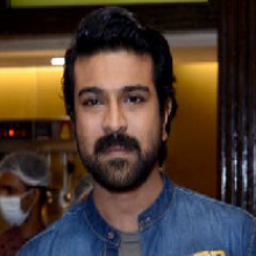

In [21]:
#@title 4. Choose the portrait { display-mode: "form" }
USE_EXAMPLE_PORTRAIT = False   #@param {type:"boolean"}

import shutil
from pathlib import Path

INPUT_DIR = Path("/content/input")
INPUT_DIR.mkdir(parents=True, exist_ok=True)

if USE_EXAMPLE_PORTRAIT:
    source = Path("/content/SadTalker/examples/source_image/people_0.png")
    portrait = INPUT_DIR / "portrait.png"
    shutil.copyfile(source, portrait)
    print("example portrait:", source)
else:
    from google.colab import files

    uploaded = files.upload()
    name = next(iter(uploaded))
    portrait = INPUT_DIR / Path(name).name
    portrait.write_bytes(uploaded[name])
    print("uploaded:", portrait)

from PIL import Image

with Image.open(portrait) as image:
    print(f"{portrait.name}: {image.size[0]}x{image.size[1]} px, mode {image.mode}")
    display(image.resize((256, 256)))

In [19]:
%%writefile /content/input/script.txt
Good morning everyone. I'm kajal, and this video was generated by Script2Presenter by Sravan .

It takes exactly two inputs: a single photograph and the text that you are listening to
right now. First, a neural text to speech model turns this script into sixteen kilohertz
audio. Then SadTalker predicts three dee facial coefficients and head motion from that audio,
and renders a twenty five frame per second video of the face speaking.

The whole pipeline runs on a free Colab T4 GPU, needs no API key and no paid service.


Writing /content/input/script.txt


The cell above wrote the script to `/content/input/script.txt`. **Edit it directly**
and re-run the generation cell — no need to re-run anything else.

Tips that measurably improve the result:

* keep sentences short and add punctuation; the TTS uses it for prosody;
* spell out numbers and abbreviations (`twenty five`, not `25`);
* ~700 characters produce roughly one minute of video;
* the first frame is taken from the portrait, so a neutral, front-facing photo works best.

## 4. Generate the video

The pipeline runs in the isolated 3.10 environment as a subprocess, so the Colab
kernel itself is never modified. A progress line is printed for every stage.

In [22]:
#@title 5. Generate the talking-head video { display-mode: "form" }
SIZE = 256          #@param [256, 512]
PREPROCESS = "crop" #@param ["crop", "full"]
ENHANCER = False    #@param {type:"boolean"}
VOICE = "en-US-GuyNeural" #@param ["en-US-AriaNeural", "en-US-GuyNeural", "en-US-JennyNeural", "en-US-DavisNeural", "en-GB-SoniaNeural", "en-IN-NeerjaNeural"]

import os, subprocess, time
from pathlib import Path

PROJECT = Path("/content/Script2Presenter")
PROJECT.mkdir(parents=True, exist_ok=True) # Ensure the project directory exists
VENV_PY = "/content/.s2p-venv/bin/python"
OUTPUT_DIR = Path("/content/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
out_video = OUTPUT_DIR / "script2presenter_demo.mp4"

# Dynamically find the absolute latest file in /content/input to avoid sticky cache
input_files = list(Path("/content/input").glob("*"))
valid_images = [f for f in input_files if f.suffix.lower() in [".png", ".jpg", ".jpeg"]]

if not valid_images:
    raise RuntimeError("No images found in /content/input. Run the 'Choose the portrait' cell or upload an image first.")

# Get the most recently modified/uploaded image
resolved_portrait = max(valid_images, key=lambda p: p.stat().st_mtime)
print(f"Using portrait: {resolved_portrait}")
print(f"Using voice: {VOICE}")

cmd = [
    VENV_PY, "-m", "s2p.cli",
    "--image", str(resolved_portrait),
    "--text-file", "/content/input/script.txt",
    "--out", str(out_video),
    "--size", str(SIZE),
    "--preprocess", PREPROCESS,
    "--voice", VOICE,
    "--json",
]
if ENHANCER:
    cmd.append("--enhancer")

env = {**os.environ, "S2P_SADTALKER_ROOT": "/content/SadTalker", "PYTHONUNBUFFERED": "1"}

print("$", " ".join(cmd), "\n", flush=True)
started = time.time()
proc = subprocess.run(cmd, cwd=PROJECT, env=env, capture_output=True, text=True)
wall = time.time() - started

print(proc.stdout)
if proc.returncode != 0:
    print(proc.stderr)
    raise SystemExit(f"Generation failed with exit code {proc.returncode}")

print(f"wall clock: {wall:.1f} s")

Using portrait: /content/input/Screenshot 2026-10-27 021420.png
Using voice: en-US-GuyNeural
$ /content/.s2p-venv/bin/python -m s2p.cli --image /content/input/Screenshot 2026-10-27 021420.png --text-file /content/input/script.txt --out /content/output/script2presenter_demo.mp4 --size 256 --preprocess crop --voice en-US-GuyNeural --json 

Environment:
  [ok] SadTalker checkout: /content/SadTalker
  [ok] SadTalker config: /content/SadTalker/src/config
  [ok] Face model (256px): /content/SadTalker/checkpoints/SadTalker_V0.0.2_256.safetensors
  [ok] Mapping network: /content/SadTalker/checkpoints/mapping_00229-model.pth.tar
  [ok] Face model weights: /content/SadTalker/gfpgan/weights/alignment_WFLW_4HG.pth
  [ok] Face model weights: /content/SadTalker/gfpgan/weights/detection_Resnet50_Final.pth
  [ok] ffmpeg executable: /usr/bin/ffmpeg
  [ok] imageio-ffmpeg backend: /content/.s2p-venv/lib/python3.10/site-packages/imageio_ffmpeg/binaries/ffmpeg-linux64-v4.2.2
  [ok] torch 2.0.1+cu117 - CUDA

In [23]:
import subprocess

# Run the voice listing via the virtual environment's python executable, specifying the correct working directory
result = subprocess.run(
    ["/content/.s2p-venv/bin/python", "-m", "s2p.cli", "--provider", "edge", "--list-voices"],
    cwd="/content/Script2Presenter",
    capture_output=True, text=True
)

if result.returncode == 0:
    # Filter and print only English voices from the CLI output
    english_voices = [line.strip() for line in result.stdout.split('\n') if "en-" in line]
    print("Available English Voices:")
    for voice in english_voices:
        print(voice)
else:
    print("Error listing voices:", result.stderr)

Available English Voices:
- en-AU-WilliamMultilingualNeural
- en-AU-NatashaNeural
- en-CA-ClaraNeural
- en-CA-LiamNeural
- en-HK-YanNeural
- en-HK-SamNeural
- en-IN-NeerjaExpressiveNeural
- en-IN-NeerjaNeural
- en-IN-PrabhatNeural
- en-IE-ConnorNeural
- en-IE-EmilyNeural
- en-KE-AsiliaNeural
- en-KE-ChilembaNeural
- en-NZ-MitchellNeural
- en-NZ-MollyNeural
- en-NG-AbeoNeural
- en-NG-EzinneNeural
- en-PH-JamesNeural
- en-PH-RosaNeural
- en-US-AvaNeural
- en-US-AndrewNeural
- en-US-EmmaNeural
- en-US-BrianNeural
- en-SG-LunaNeural
- en-SG-WayneNeural
- en-ZA-LeahNeural
- en-ZA-LukeNeural
- en-TZ-ElimuNeural
- en-TZ-ImaniNeural
- en-GB-LibbyNeural
- en-GB-MaisieNeural
- en-GB-RyanNeural
- en-GB-SoniaNeural
- en-GB-ThomasNeural
- en-US-AnaNeural
- en-US-AndrewMultilingualNeural
- en-US-AriaNeural
- en-US-AvaMultilingualNeural
- en-US-BrianMultilingualNeural
- en-US-ChristopherNeural
- en-US-EmmaMultilingualNeural
- en-US-EricNeural
- en-US-GuyNeural
- en-US-JennyNeural
- en-US-MichelleNeur

In [24]:
#@title Real-time video generation based on your selected options { display-mode: "form" }
import os, subprocess, sys, time
from pathlib import Path

# These parameters pull from the variables configured in Step 5 (cell-026)
try:
    selected_voice = VOICE
    selected_size = SIZE
    selected_preprocess = PREPROCESS
    selected_enhancer = ENHANCER
except NameError:
    selected_voice = "en-US-JennyNeural"
    selected_size = 256
    selected_preprocess = "crop"
    selected_enhancer = False

PROJECT = Path("/content/Script2Presenter")
VENV_PY = "/content/.s2p-venv/bin/python"
OUTPUT_DIR = Path("/content/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
out_video = OUTPUT_DIR / "script2presenter_demo.mp4"

# Dynamically find the absolute latest portrait image file uploaded to /content/input
input_files = list(Path("/content/input").glob("*"))
valid_images = [f for f in input_files if f.suffix.lower() in [".png", ".jpg", ".jpeg"]]

if not valid_images:
    raise RuntimeError("No images found in /content/input. Run the 'Choose the portrait' cell or upload an image first.")

resolved_portrait = max(valid_images, key=lambda p: p.stat().st_mtime)

cmd = [
    VENV_PY, "-m", "s2p.cli",
    "--image", str(resolved_portrait),
    "--text-file", "/content/input/script.txt",
    "--out", str(out_video),
    "--size", str(selected_size),
    "--preprocess", selected_preprocess,
    "--voice", selected_voice,
    "--json"
]
if selected_enhancer:
    cmd.append("--enhancer")

env = {**os.environ, "S2P_SADTALKER_ROOT": "/content/SadTalker", "PYTHONUNBUFFERED": "1"}

print(f"Using portrait: {resolved_portrait}")
print(f"Using voice: {selected_voice}")
print("Executing command:", " ".join(cmd), "\n", flush=True)

started = time.time()
# Run using Popen to print progress lines in real-time
process = subprocess.Popen(cmd, cwd=PROJECT, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

while True:
    line = process.stdout.readline()
    if not line and process.poll() is not None:
        break
    if line:
        print(line.strip(), flush=True)

rc = process.poll()
wall = time.time() - started

if rc != 0:
    raise RuntimeError(f"Generation failed with exit code {rc}")
else:
    print(f"\nSUCCESS! Video generated using '{selected_voice}' and your latest portrait in {wall:.1f} seconds. Please proceed to run Step 6 below to watch and listen.")

Using portrait: /content/input/Screenshot 2026-10-27 021420.png
Using voice: en-US-GuyNeural
Executing command: /content/.s2p-venv/bin/python -m s2p.cli --image /content/input/Screenshot 2026-10-27 021420.png --text-file /content/input/script.txt --out /content/output/script2presenter_demo.mp4 --size 256 --preprocess crop --voice en-US-GuyNeural --json 

Environment:
[ok] SadTalker checkout: /content/SadTalker
[ok] SadTalker config: /content/SadTalker/src/config
[ok] Face model (256px): /content/SadTalker/checkpoints/SadTalker_V0.0.2_256.safetensors
[ok] Mapping network: /content/SadTalker/checkpoints/mapping_00229-model.pth.tar
[ok] Face model weights: /content/SadTalker/gfpgan/weights/alignment_WFLW_4HG.pth
[ok] Face model weights: /content/SadTalker/gfpgan/weights/detection_Resnet50_Final.pth
[ok] ffmpeg executable: /usr/bin/ffmpeg
[ok] imageio-ffmpeg backend: /content/.s2p-venv/lib/python3.10/site-packages/imageio_ffmpeg/binaries/ffmpeg-linux64-v4.2.2
[ok] torch 2.0.1+cu117 - CUDA 

In [25]:
#@title 6. Watch and download the result { display-mode: "form" }
import json
from pathlib import Path
from IPython.display import Audio, Markdown, Video, display

manifests = sorted(Path("/content/Script2Presenter/outputs").glob("*/manifest.json"))
manifest_path = manifests[-1]
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

generation = manifest["generation"]
timings = manifest["timings"]
tts = manifest["tts"]
audio = manifest["audio"]

display(Markdown(f'''
### Result

| | |
|---|---|
| video | `{generation["video_path"]}` |
| duration | **{generation["duration_s"]:.1f} s** ({generation["frames"]} frames @ 25 fps) |
| resolution | {generation["size"]} px, framing `{generation["preprocess"]}`, enhancer `{generation["enhancer"]}` |
| speech | `{tts["provider"]}` / `{tts["voice"]}` ({audio["duration_s"]:.1f} s, {audio["sample_rate"]} Hz mono) |
| time | TTS {timings["tts_s"]:.1f} s + render {timings["sadtalker_s"]:.1f} s = **{timings["total_s"]:.1f} s** |
| device | `{generation["device"]}` |
| manifest | `{manifest_path}` |
'''))

display(Video(generation["video_path"], embed=True, width=640))
display(Audio(audio["path"]))


### Result

| | |
|---|---|
| video | `/content/Script2Presenter/outputs/20261026_205040_78e257/sadtalker/20261026_205042_09008d/source##driven_audio.mp4` |
| duration | **37.4 s** (935 frames @ 25 fps) |
| resolution | 256 px, framing `crop`, enhancer `None` |
| speech | `edge` / `en-US-GuyNeural` (37.4 s, 16000 Hz mono) |
| time | TTS 1.0 s + render 340.7 s = **341.7 s** |
| device | `cuda` |
| manifest | `/content/Script2Presenter/outputs/20261026_205040_78e257/manifest.json` |


In [26]:
#@title 7. Download the MP4 { display-mode: "form" }
try:
    from google.colab import files

    files.download(str(out_video))
except Exception as exc:  # not running inside Colab
    print("MP4:", out_video)
    print(exc)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Optional: the web UI

The same pipeline is also available as a Gradio app. The cell starts it in the
background and prints the public `*.gradio.live` URL (valid for 72 hours).

Locally this is simply:

```bash
python -m s2p.ui            # http://localhost:7860
```

The UI adds a *Check environment* button, every advanced SadTalker switch
(resolution, framing, still mode, pose style, batch size, GFPGAN) and a download
button for the MP4.

In [27]:
#@title 8. Launch the Gradio UI (optional) { display-mode: "form" }
import os, re, subprocess, time
from pathlib import Path

PROJECT = Path("/content/Script2Presenter")
VENV_PY = "/content/.s2p-venv/bin/python"
log_path = Path("/content/output/gradio.log")
log_path.parent.mkdir(parents=True, exist_ok=True)

if "ui_process" in globals() and ui_process.poll() is None:
    ui_process.terminate()
    time.sleep(2)

ui_process = subprocess.Popen(
    [VENV_PY, "-m", "s2p.ui", "--share", "--port", "7860"],
    cwd=PROJECT,
    env={**os.environ, "S2P_SADTALKER_ROOT": "/content/SadTalker", "PYTHONUNBUFFERED": "1"},
    stdout=log_path.open("w"),
    stderr=subprocess.STDOUT,
)

public_url = None
for _ in range(180):
    time.sleep(1)
    text = log_path.read_text(errors="ignore")
    match = re.search(r"https://[a-z0-9-]+\.gradio\.live", text)
    if match:
        public_url = match.group(0)
        break
    if ui_process.poll() is not None:
        break

if public_url:
    print("Public UI:", public_url)
else:
    print("UI did not start (is this a local Jupyter?). Last log lines:\n")
    print(log_path.read_text(errors="ignore")[-3000:])
    print("Local URL (if any) is usually http://127.0.0.1:7860")

Public UI: https://3c7946d7ede3a55df6.gradio.live


## Optional: Streamlit Dashboard

Run the cells below to launch a Streamlit dashboard. It uses the exact same underlying pipeline without changing any existing code.

In [28]:
import os
os.makedirs("/content/Script2Presenter/s2p", exist_ok=True)

with open("/content/Script2Presenter/s2p/app_streamlit.py", "w", encoding="utf-8") as f:
    f.write('''import streamlit as st
import os
import sys
import time
from pathlib import Path
from PIL import Image

# Add the project root to sys.path so we can import s2p safely
PROJECT_ROOT = Path(__file__).resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from s2p.pipeline import Script2Presenter, PipelineError
from s2p.tts import list_voices

# Page Config
st.set_page_config(page_title="Script2Presenter Dashboard", layout="wide")

@st.cache_resource
def load_pipeline():
    # Initialize pipeline with the custom venv and SadTalker root settings
    os.environ["S2P_SADTALKER_ROOT"] = "/content/SadTalker"
    return Script2Presenter()

try:
    app = load_pipeline()
except Exception as e:
    st.error(f"Failed to initialize Script2Presenter: {e}")
    st.stop()

st.title("🎥 Script2Presenter Dashboard")
st.write("Generate a talking-head video from a single portrait and a text script using a T4 GPU.")

col1, col2 = st.columns([1, 1])

with col1:
    st.header("Inputs & Settings")

    # 1. Image Upload
    uploaded_file = st.file_uploader("Upload Portrait (JPG/PNG)", type=["png", "jpg", "jpeg"])

    # 2. Script Input
    script_text = st.text_area(
        "Script",
        value="Good morning! This video is generated dynamically using our Streamlit dashboard.",
        height=150
    )

    # 3. Settings
    provider = st.selectbox("Speech Engine", ["auto", "edge", "piper", "gtts"], index=0)

    # Voice retrieval
    try:
        voices = list_voices("edge")
    except Exception:
        voices = ["en-US-JennyNeural", "en-US-AriaNeural", "en-US-GuyNeural"]

    voice = st.selectbox("Voice", voices, index=0)

    col1_a, col1_b = st.columns(2)
    with col1_a:
        size = st.radio("Resolution", [256, 512], index=0)
    with col1_b:
        preprocess = st.radio("Framing", ["crop", "full"], index=0)

    enhancer = st.checkbox("GFPGAN Face Enhancer (Slower but sharper)", value=False)

    generate_btn = st.button("Generate Video", type="primary")

with col2:
    st.header("Output")

    if uploaded_file is not None:
        image = Image.open(uploaded_file)
        st.image(image, caption="Uploaded Portrait", width=256)

    if generate_btn:
        if not uploaded_file:
            st.warning("Please upload a portrait image first.")
        elif not script_text.strip():
            st.warning("Please write a script.")
        else:
            # Save uploaded file to temp location
            temp_input_dir = Path("/content/input")
            temp_input_dir.mkdir(parents=True, exist_ok=True)
            temp_image_path = temp_input_dir / uploaded_file.name
            temp_image_path.write_bytes(uploaded_file.getvalue())

            progress_bar = st.progress(0)
            status_text = st.empty()

            def update_progress(fraction, message):
                progress_bar.progress(float(fraction))
                status_text.info(message)

            try:
                t0 = time.time()
                result = app.run(
                    image_path=temp_image_path,
                    script=script_text,
                    provider=provider,
                    voice=voice,
                    size=int(size),
                    preprocess=preprocess,
                    enhancer="gfpgan" if enhancer else None,
                    progress=update_progress
                )
                elapsed = time.time() - t0

                status_text.success(f"Video generated successfully in {elapsed:.1f} seconds!")

                # Render Output Video
                st.video(str(result.video_path))

                # Provide download button
                with open(result.video_path, "rb") as f:
                    st.download_button(
                        label="Download MP4",
                        data=f,
                        file_name="talking_head.mp4",
                        mime="video/mp4"
                    )
            except PipelineError as e:
                status_text.error(f"Pipeline Error: {e}")
            except Exception as e:
                status_text.error(f"Unexpected Error: {e}")
''')
print("Streamlit file written successfully.")

Streamlit file written successfully.


In [29]:
#@title Launch Streamlit via Tunnel
import subprocess
import os
import sys
import time

# Fallback to system pip/python if the local virtualenv path differs
python_bin = "/content/.s2p-venv/bin/python"
pip_bin = "/content/.s2p-venv/bin/pip"
if not os.path.exists(pip_bin):
    python_bin = sys.executable
    pip_bin = f"{sys.executable} -m pip"

# 1. Install localtunnel
subprocess.run(["npm", "install", "-g", "localtunnel"], capture_output=True)

# 2. Install streamlit in the runtime environment
if " " in pip_bin:
    subprocess.run(pip_bin.split() + ["install", "-q", "streamlit"], capture_output=True)
else:
    subprocess.run([pip_bin, "install", "-q", "streamlit"], capture_output=True)

# 3. Print IP address (needed to bypass Localtunnel protection screen)
print("Your Tunnel Password (IP Address): ")
!curl -s ipv4.icanhazip.com
print("\nClick the link below, paste this IP address into the 'Tunnel Password' input, and submit.\n")

# 4. Start Streamlit in the background
streamlit_cmd = [python_bin, "-m", "streamlit", "run", "/content/Script2Presenter/s2p/app_streamlit.py", "--server.port", "8501", "--server.address", "0.0.0.0"]
if python_bin != "/content/.s2p-venv/bin/python":
    streamlit_cmd = [python_bin, "-m", "streamlit", "run", "/content/Script2Presenter/s2p/app_streamlit.py", "--server.port", "8501", "--server.address", "0.0.0.0"]
else:
    streamlit_cmd = ["/content/.s2p-venv/bin/streamlit", "run", "/content/Script2Presenter/s2p/app_streamlit.py", "--server.port", "8501", "--server.address", "0.0.0.0"]

streamlit_proc = subprocess.Popen(streamlit_cmd)
time.sleep(3)

# 5. Start Localtunnel tunnel
!npx localtunnel --port 8501

Your Tunnel Password (IP Address): 
34.50.168.126

Click the link below, paste this IP address into the 'Tunnel Password' input, and submit.

⠙⠹⠸⠼⠴your url is: https://rich-spiders-fix.loca.lt
^C


## Troubleshooting

| symptom | fix |
|---|---|
| `numpy drifted to 2.x` | re-run the setup cell; it re-installs `numpy==1.23.5` and refuses to continue otherwise |
| `ModuleNotFoundError: cv2` / `libGL.so.1` | the setup cell installs `opencv-python-headless`; make sure you used the venv python |
| `No face was detected` | use a frontal portrait, at least 256x256, one face, no heavy occlusion |
| `torch.cuda.is_available() == False` | enable the T4 runtime and re-run the GPU check |
| `edge-tts` rate limited | set `PROVIDER="piper"` (fully offline) in the generation cell |
| out of memory at 512 px | use `SIZE = 256`; 512 px needs roughly 4 GB more VRAM |
| `ffmpeg not found` | SadTalker muxes audio with `ffmpeg`; Colab has it, locally install it |
| UI does not start | run it in a terminal (`python -m s2p.ui`) instead of inside the notebook |

Every run writes `outputs/<timestamp>/manifest.json` with the exact inputs,
timings, device, checkpoint size and output paths — the data used for the
evaluation section of the report.

## How it works

**Stage 1 — speech.** `s2p.tts` normalises the script, splits it at sentence
boundaries (1800 character chunks) and synthesises each chunk with the first
working provider:

1. `edge-tts` — Microsoft neural voices, 24 kHz MP3, best quality, needs network.
2. `piper-tts` — VITS ONNX model, 16 kHz WAV, fully offline (63 MB per voice).
3. `gTTS` — Google Translate endpoint, last resort.

The result is always converted to **16 kHz mono PCM WAV**, which is what
SadTalker's mel front-end expects.

**Stage 2 — animation.** `s2p.sadtalker_backend` calls the official modules in the
same order as SadTalker's own `inference.py`:

1. `CropAndExtract` — face detection (facexlib), 3DMM reconstruction, alignment.
2. `Audio2Coeff` — audio → pose coefficients + expression coefficients (25 fps).
3. `AnimateFromCoeff` — renders the frames and muxes the audio track with ffmpeg.

**Why a manifest.** Every run records timings, device, voice, resolution and file
paths, so speed and quality can be compared across runs without guesswork.

## Credits and licence

* **SadTalker** — *SadTalker: Learning Realistic 3D Motion Coefficients for Stylized
  Audio-Driven Single Image Talking Face Animation*, CVPR 2023,
  [OpenTalker/SadTalker](https://github.com/OpenTalker/SadTalker), **Apache-2.0**.
  Checkpoints are downloaded from the official release assets only.
* **GFPGAN / facexlib** — Tencent ARC, Apache-2.0 / MIT.
* **Piper** — rhasspy, MIT; voices from `rhasspy/piper-voices`.
* **edge-tts** — an unofficial client for the free Microsoft Edge read-aloud
  endpoint; the voices remain subject to Microsoft's terms.
* The portrait used by default (`people_0.png`) ships with SadTalker's examples.

Use only images and scripts you have the rights to, and say clearly that the video
is synthetic when you publish it.